# Cervical Cytology — NEW (Upgraded) Pipeline

A **solution** pipeline that closes gaps in the cervical-cytology DL literature (it does **not** reproduce the
legacy audit). Run top-to-bottom. Each research question (RQ1–RQ7) is pre-registered with a *positive*
hypothesis and its evidence is produced below.

**What it delivers:** leakage-safe cluster-grouped 80/10/10 split with a **sealed test** (RQ1) · domain
generalization via stain-norm + SSL (RQ2) · calibrated, risk-aware abstention (RQ3) · safe cross-taxonomy
E0/E1/E-morph evaluation (RQ4) · **CellGAN** minority-class rescue (RQ5) · distilled B0 vs **published SOTA**
(RQ6) · multimodal fusion + explainability (RQ7).

B4 teacher → distilled B0 student @224px on the RTX 5060 Ti. Independent of `Legacy_src/`. Outputs → `results/`.
Resumable training (timestamped JSON logs; best+last checkpoints). **Every value and every figure is persisted
as JSON/CSV** for exact reproduction.

## 0. Setup

In [1]:
import sys, os, glob, json
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))
import torch, config as C
C.set_seed()
print('device:', C.DEVICE, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
from IPython.display import Image, display
FIG = C.FIGDIR
def show(*stems):
    for s in stems:
        p = s if s.endswith('.png') else s + '.png'
        display(Image(p)) if os.path.exists(p) else print('(missing)', os.path.basename(p))

device: cuda | NVIDIA GeForce RTX 5060 Ti


## 0b. Preflight — verify every dataset + guard every legacy failure
Checks all 5 datasets are downloaded (auto-fetches any missing), scans for 0-byte/corrupt images, verifies the
`ssl.py`-shadow / drive-letter-case fixes, and reports GPU/VRAM/BF16. Writes `results/metrics/preflight.json`.

In [2]:
import preflight
pf = preflight.run()
assert pf['ok'], 'preflight found issues — see results/metrics/preflight.json before training'

Datasets: {'sipakmed': 5015, 'herlev': 1834, 'apacc': 1125, 'hicervix': 40229, 'cric': 400}
Missing: none
Corrupt/zero-byte: none
Env: {'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 5060 Ti', 'vram_total_gb': 17.1, 'bf16_supported': True}
Code hazards: {'ssl_shadow': True, 'split_paths_case_ok': True}
PREFLIGHT OK


## 0c. Research framing — pre-registered RQs / hypotheses / contributions
Literature-gap-anchored, positive hypotheses (no experiment is set up to fail). Saved to
`results/metrics/research_framing.json`.

In [3]:
import research
fr = research.framing(); research.dump()
for g in fr['research_gaps']:
    print(f"{g['id']}: {g['title']}")
print()
for rq in fr['research_questions']:
    print(f"{rq['id']} [{rq['gap']}] {rq['label']}\n    H: {rq['hypothesis']}\n    target: {rq['success_metric']}\n")

G1: Non-reproducible, leakage-prone evaluation
G2: Single-dataset training; cross-domain generalization unsolved
G3: Overconfidence; no uncertainty or abstention
G4: Fragmented, incompatible label taxonomies
G5: Severe imbalance; rare high-grade / minority classes missed
G6: Accuracy-efficiency trade-off blocks point-of-care use
G7: Black-box, image-only predictions limit clinical trust

RQ1 [G1] A leakage-safe, reproducible benchmark
    H: H1: the grouped, sealed-test protocol yields a reproducible benchmark whose 5-class metrics (balanced acc, macro-F1, OvR-AUROC) are stable across seeds within their 95% bootstrap CIs and are reproducible bit-for-bit from the released split.
    target: bootstrap-CI-stable metrics across >=3 seeds; split/seed-reproducible; zero cluster overlap.

RQ2 [G2] Domain-generalizable classifier
    H: H2: the domain-generalization stack achieves external binary balanced accuracy and AUROC clearly above the majority baseline and above the un-normalized backbo

## 0d. (Optional) One-click full run
Runs the whole pipeline end-to-end (preflight → EDA → train teacher+student → evaluate). **Long** (hours on one
GPU) but resumable — re-run the cell to continue after any interruption. Leave commented to run the steps
individually below.

In [4]:
# import run
# run.eda()                 # all-dataset EDA + split + research framing
# import train; train.main()  # teacher (two-stage) -> distilled student  (auto-resumes)
# run.evaluate('student')   # sealed test + cross-dataset E0/E1/E-morph + calibration + efficiency
print('Uncomment to run everything in one go (resumable). Or run the per-step cells below.')

Uncomment to run everything in one go (resumable). Or run the per-step cells below.


## 1. EDA — ALL datasets + leakage-safe split (RQ1/RQ4)
`run.eda()` profiles SIPaKMeD + Herlev + APACC + HiCervix + CRIC (native-class counts, E0 mapping coverage +
**excluded fraction**, image-size stats, corrupt scan, montages) and builds the sealed cluster-grouped split.
All JSON+CSV → `results/metrics/eda/`, figures → `results/figures/eda/`.

f:\Cervaical Cancer\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All-dataset EDA:
  sipakmed  n=  4049  excl_frac=0.000  corrupt=0  classes=5
  herlev    n=   917  excl_frac=0.107  corrupt=0  classes=7
  apacc     n=  1125  excl_frac=0.000  corrupt=0  classes=2
  hicervix  n=  8051  excl_frac=0.401  corrupt=0  classes=4
  cric      n= 11534  excl_frac=0.000  corrupt=0  classes=6
[class-analysis] 5-class ...
  silhouette=0.0888  sig features (q<.05)=53/53
[class-analysis] binary ...
  silhouette=0.0949  sig features (q<.05)=50/53
[class-analysis] JSON+CSV -> f:\Cervaical Cancer\results\metrics\class_analysis | figures -> f:\Cervaical Cancer\results\figures\class_analysis
{
  "n_cells": 4049,
  "n_clusters": 966,
  "train": {
    "cells": 3238,
    "clusters": 773,
    "per_class": {
      "Superficial-Intermediate": 665,
      "Parabasal": 629,
      "Metaplastic": 634,
      "Koilocytotic": 660,
      "Dyskeratotic": 650
    }
  },
  "val": {
    "cells": 405,
    "clusters": 96,
    "per_class": {
      "Superficial-Intermediate": 82,
      "Paraba

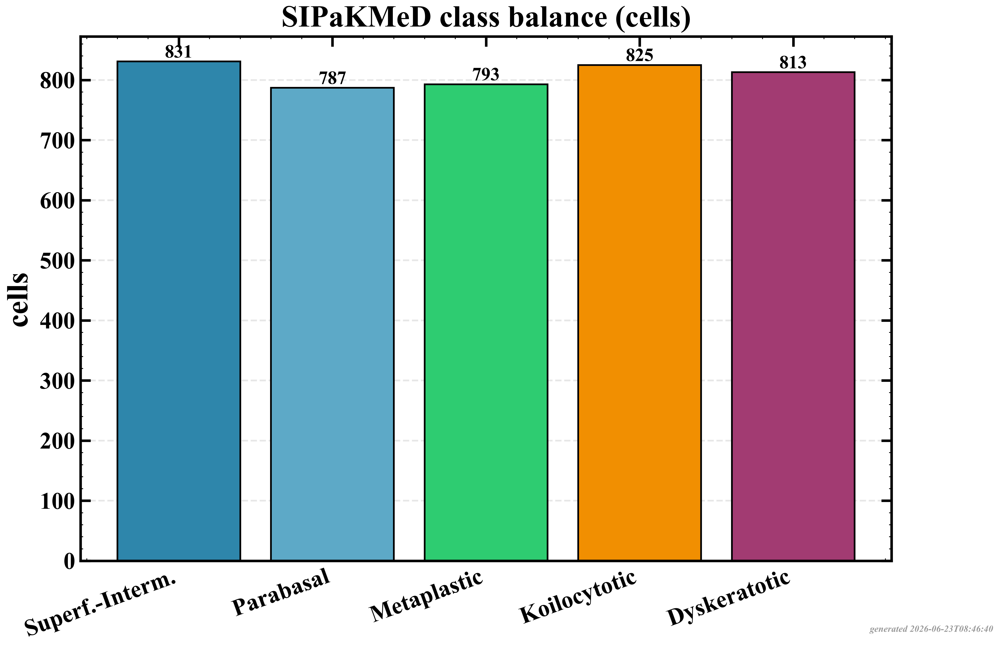

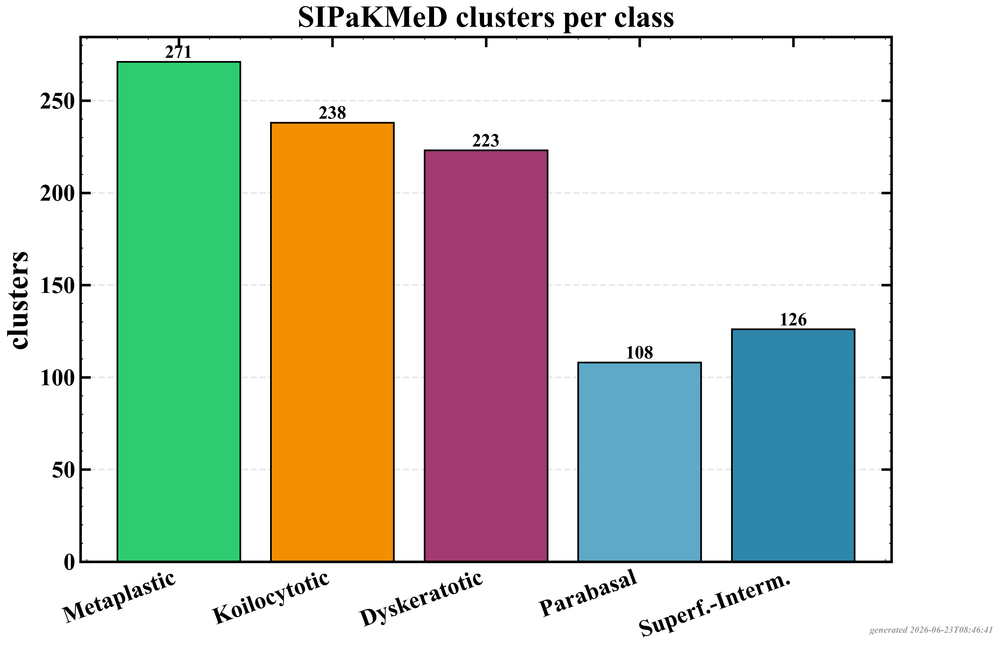

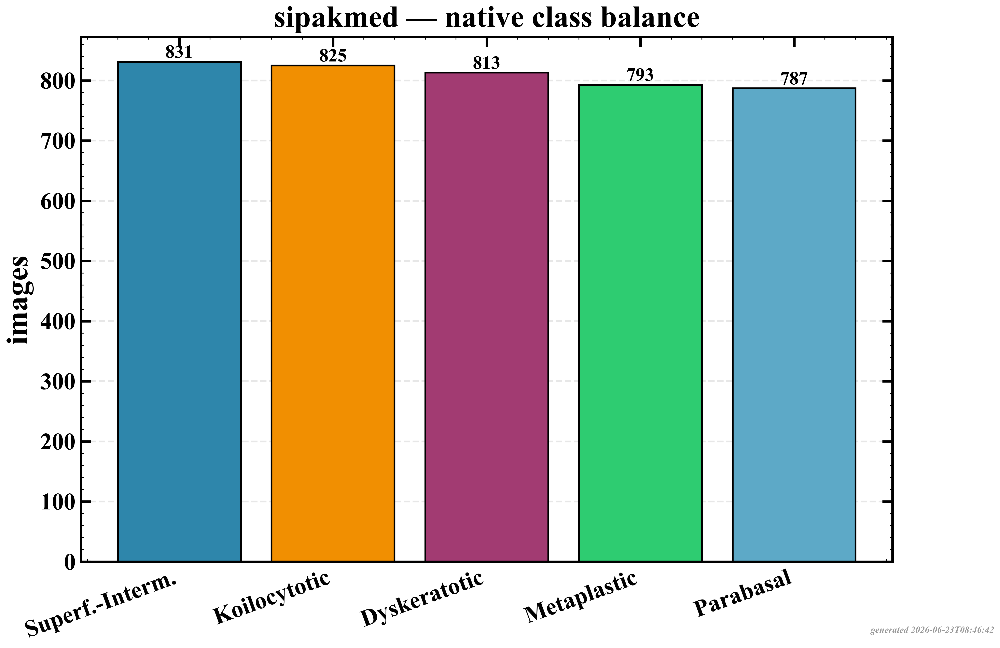

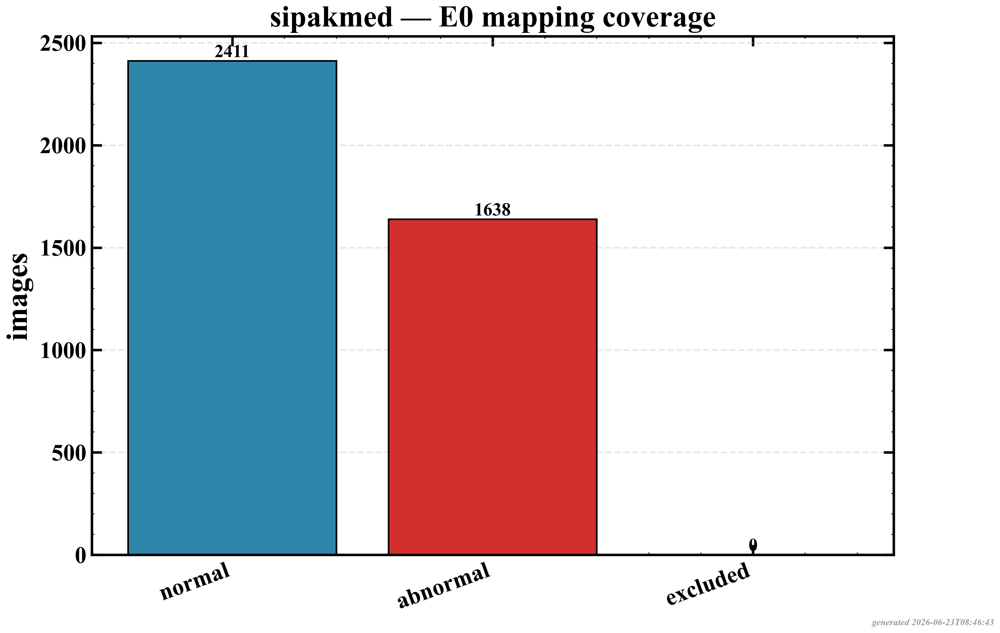

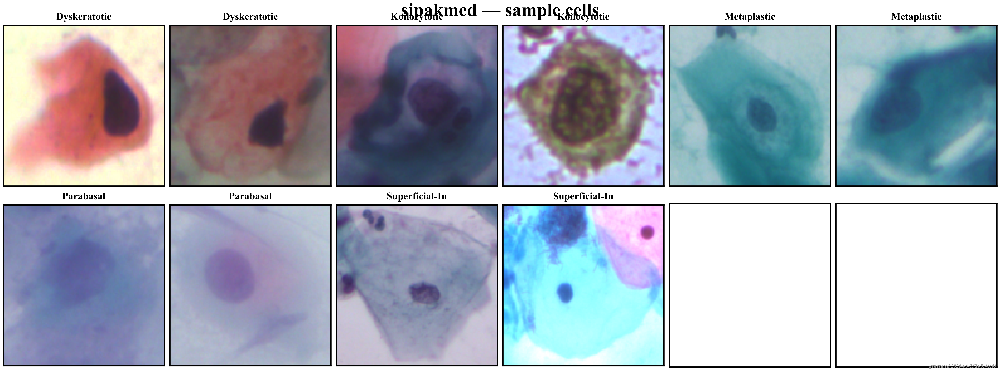

...

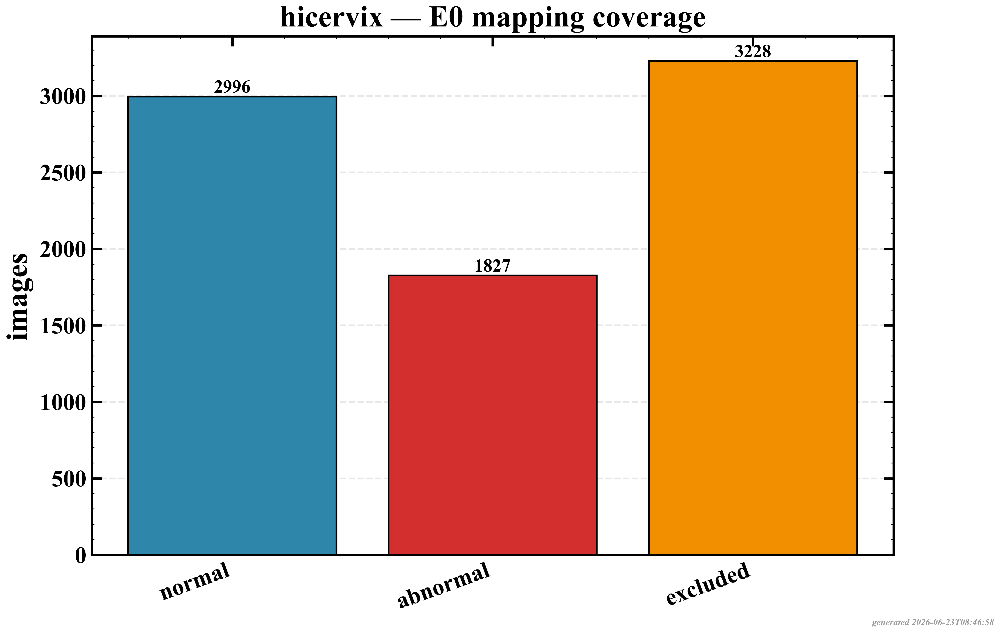

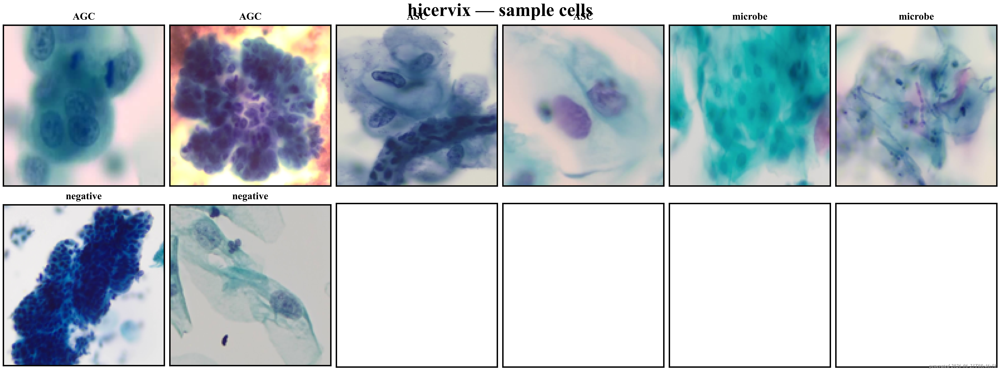

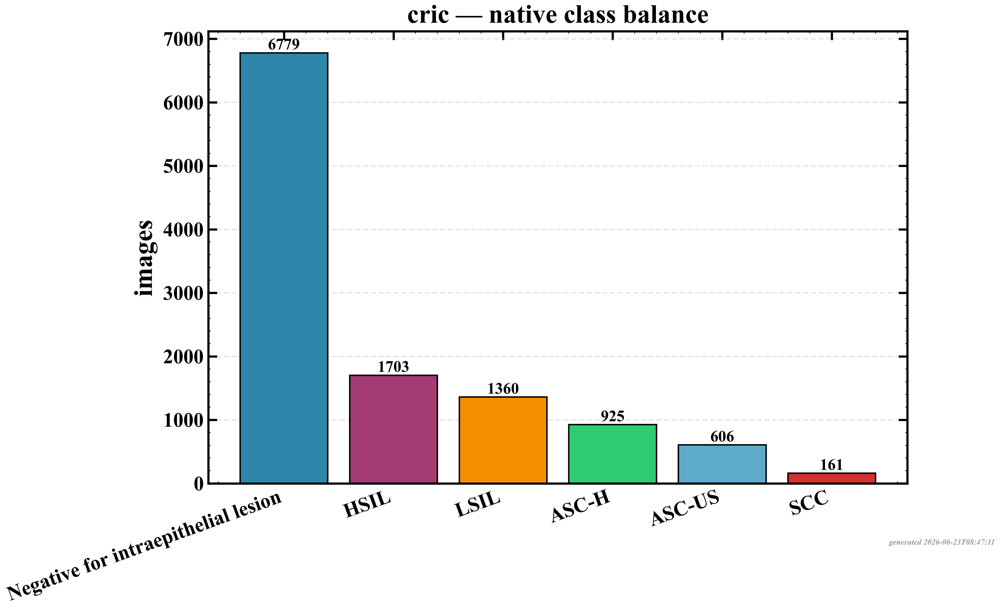

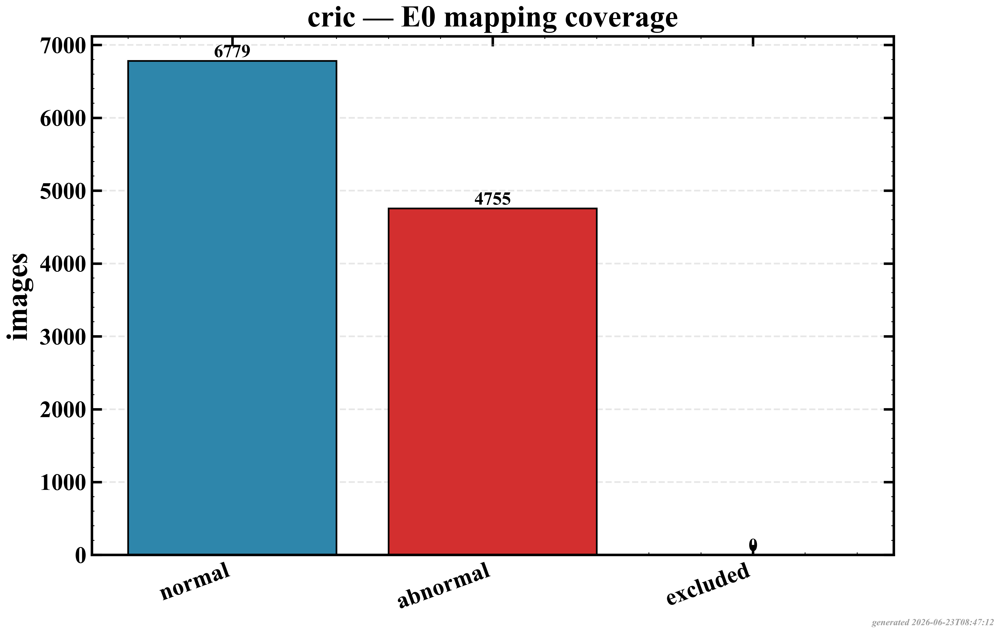

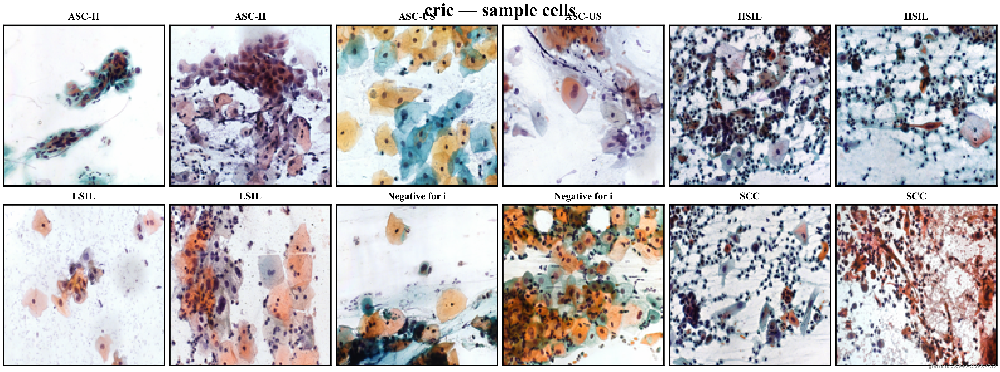

In [2]:
import run
rep = run.eda()
print('overview:', open(os.path.join(C.METRICDIR,'eda','eda_overview.csv')).read())
show(os.path.join(FIG,'eda_class_balance'), os.path.join(FIG,'eda_cluster_balance'))
for ds in ['sipakmed','herlev','apacc','hicervix','cric']:
    show(os.path.join(FIG,'eda',f'{ds}_classes'), os.path.join(FIG,'eda',f'{ds}_e0coverage'), os.path.join(FIG,'eda',f'{ds}_montage'))

## 2. Train — B4 teacher (two-stage) → distilled B0 student (RQ2/RQ6). Resumable; test sealed.
Training + early stopping use **train+val only**. Arms (each a full run): `train.main(distill=False)` (A2 scratch),
`kd_mode='buggy'` (A2 control), `imbalance='focal'|'oversample'` (A6), `aug='geometric'|'none'` (A5),
`stain='macenko'|'reinhard'` (A4, RQ2), `student_backbone='maxcervixt'|'ccannet'|'cervixpert'` (RQ6),
`ssl_init=True` (A9, RQ2).

In [7]:
import train
train.main()        # auto-resumes from the last checkpoint

Run id: 20260622_183134  ->  f:\Cervaical Cancer\results\logs\run_20260622_183134.json
Split: grouped | stain: none | student img: 224 | teacher img: 380 | EMA: True | Train counts: {'Superficial-Intermediate': 665, 'Parabasal': 629, 'Metaplastic': 634, 'Koilocytotic': 660, 'Dyskeratotic': 650} | total 3238 (test: 406 cells)
Teacher [efficientnet_b4] params: 18.5M


[teacher-s1] ep 01/50  loss=0.7258 val_loss=0.5020  acc=0.7869 val_acc=0.8099  lr=1.0e-03  (55s)  *best


[teacher-s1] ep 02/50  loss=0.5918 val_loss=0.4579  acc=0.8527 val_acc=0.8198  lr=1.0e-03  (44s)  *best


[teacher-s1] ep 03/50  loss=0.5514 val_loss=0.4117  acc=0.8697 val_acc=0.8346  lr=1.0e-03  (44s)  *best


[teacher-s1] ep 04/50  loss=0.5376 val_loss=0.3641  acc=0.8749 val_acc=0.8691  lr=1.0e-03  (39s)  *best


[teacher-s1] ep 05/50  loss=0.5452 val_loss=0.3272  acc=0.8762 val_acc=0.8914  lr=1.0e-03  (41s)  *best


[teacher-s1] ep 06/50  loss=0.5455 val_loss=0.3361  acc=0.8718 val_acc=0.8741  lr=1.0e-03  (40s)


[teacher-s1] ep 07/50  loss=0.5247 val_loss=0.3451  acc=0.8867 val_acc=0.8691  lr=1.0e-03  (40s)


[teacher-s1] ep 08/50  loss=0.5226 val_loss=0.3439  acc=0.8867 val_acc=0.8914  lr=1.0e-03  (40s)


[teacher-s1] ep 09/50  loss=0.5156 val_loss=0.3270  acc=0.8897 val_acc=0.8790  lr=1.0e-03  (40s)  *best


[teacher-s1] ep 10/50  loss=0.5031 val_loss=0.3104  acc=0.8968 val_acc=0.8840  lr=1.0e-03  (40s)  *best


[teacher-s1] ep 11/50  loss=0.5161 val_loss=0.3088  acc=0.8891 val_acc=0.8963  lr=1.0e-03  (40s)  *best


[teacher-s1] ep 12/50  loss=0.5238 val_loss=0.3159  acc=0.8867 val_acc=0.8864  lr=1.0e-03  (40s)


[teacher-s1] ep 13/50  loss=0.5124 val_loss=0.3183  acc=0.8879 val_acc=0.8914  lr=1.0e-03  (40s)


[teacher-s1] ep 14/50  loss=0.4990 val_loss=0.3108  acc=0.8907 val_acc=0.8864  lr=1.0e-03  (43s)


[teacher-s1] ep 15/50  loss=0.4967 val_loss=0.3026  acc=0.8968 val_acc=0.8963  lr=1.0e-03  (45s)  *best


[teacher-s1] ep 16/50  loss=0.4979 val_loss=0.3093  acc=0.8965 val_acc=0.8963  lr=1.0e-03  (44s)


[teacher-s1] ep 17/50  loss=0.4910 val_loss=0.3073  acc=0.9006 val_acc=0.8889  lr=1.0e-03  (45s)


[teacher-s1] ep 18/50  loss=0.4922 val_loss=0.3113  acc=0.9018 val_acc=0.8914  lr=1.0e-03  (44s)


[teacher-s1] ep 19/50  loss=0.4840 val_loss=0.3202  acc=0.9036 val_acc=0.8889  lr=1.0e-03  (44s)


[teacher-s1] ep 20/50  loss=0.4914 val_loss=0.3157  acc=0.9049 val_acc=0.8840  lr=1.0e-03  (41s)


[teacher-s1] ep 21/50  loss=0.4547 val_loss=0.3145  acc=0.9253 val_acc=0.8889  lr=3.0e-04  (39s)


[teacher-s1] ep 22/50  loss=0.4452 val_loss=0.3140  acc=0.9179 val_acc=0.8889  lr=3.0e-04  (39s)


[teacher-s1] ep 23/50  loss=0.4409 val_loss=0.3107  acc=0.9265 val_acc=0.8914  lr=3.0e-04  (40s)
[teacher-s1] early stop at ep 23 (best val_loss=0.3026 @ ep15)


[teacher-s2] ep 01/120  loss=0.4381 val_loss=0.3007  acc=0.9197 val_acc=0.8988  lr=1.0e-05  (74s)  *best


[teacher-s2] ep 02/120  loss=0.4316 val_loss=0.2890  acc=0.9302 val_acc=0.9037  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 03/120  loss=0.4335 val_loss=0.2888  acc=0.9259 val_acc=0.9111  lr=1.0e-05  (66s)  *best


[teacher-s2] ep 04/120  loss=0.4250 val_loss=0.2858  acc=0.9293 val_acc=0.9037  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 05/120  loss=0.4255 val_loss=0.2864  acc=0.9287 val_acc=0.9086  lr=1.0e-05  (65s)


[teacher-s2] ep 06/120  loss=0.4120 val_loss=0.2796  acc=0.9376 val_acc=0.9086  lr=1.0e-05  (66s)  *best


[teacher-s2] ep 07/120  loss=0.4244 val_loss=0.2809  acc=0.9367 val_acc=0.9062  lr=1.0e-05  (65s)


[teacher-s2] ep 08/120  loss=0.4135 val_loss=0.2767  acc=0.9355 val_acc=0.9086  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 09/120  loss=0.4169 val_loss=0.2720  acc=0.9355 val_acc=0.9062  lr=1.0e-05  (67s)  *best


[teacher-s2] ep 10/120  loss=0.4093 val_loss=0.2703  acc=0.9345 val_acc=0.9136  lr=1.0e-05  (70s)  *best


[teacher-s2] ep 11/120  loss=0.4092 val_loss=0.2678  acc=0.9385 val_acc=0.9086  lr=1.0e-05  (69s)  *best


[teacher-s2] ep 12/120  loss=0.3985 val_loss=0.2657  acc=0.9441 val_acc=0.9062  lr=1.0e-05  (70s)  *best


[teacher-s2] ep 13/120  loss=0.4032 val_loss=0.2680  acc=0.9382 val_acc=0.9062  lr=1.0e-05  (68s)


[teacher-s2] ep 14/120  loss=0.3977 val_loss=0.2650  acc=0.9407 val_acc=0.9062  lr=1.0e-05  (62s)  *best


[teacher-s2] ep 15/120  loss=0.4021 val_loss=0.2633  acc=0.9407 val_acc=0.9086  lr=1.0e-05  (70s)  *best


[teacher-s2] ep 16/120  loss=0.3932 val_loss=0.2618  acc=0.9466 val_acc=0.9136  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 17/120  loss=0.3872 val_loss=0.2617  acc=0.9484 val_acc=0.9136  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 18/120  loss=0.3848 val_loss=0.2575  acc=0.9494 val_acc=0.9210  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 19/120  loss=0.3821 val_loss=0.2561  acc=0.9524 val_acc=0.9185  lr=1.0e-05  (66s)  *best


[teacher-s2] ep 20/120  loss=0.3810 val_loss=0.2548  acc=0.9503 val_acc=0.9210  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 21/120  loss=0.3808 val_loss=0.2516  acc=0.9552 val_acc=0.9185  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 22/120  loss=0.3874 val_loss=0.2508  acc=0.9481 val_acc=0.9235  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 23/120  loss=0.3803 val_loss=0.2527  acc=0.9521 val_acc=0.9185  lr=1.0e-05  (65s)


[teacher-s2] ep 24/120  loss=0.3804 val_loss=0.2506  acc=0.9500 val_acc=0.9210  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 25/120  loss=0.3780 val_loss=0.2500  acc=0.9478 val_acc=0.9210  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 26/120  loss=0.3681 val_loss=0.2505  acc=0.9586 val_acc=0.9185  lr=1.0e-05  (65s)


[teacher-s2] ep 27/120  loss=0.3746 val_loss=0.2492  acc=0.9515 val_acc=0.9160  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 28/120  loss=0.3744 val_loss=0.2449  acc=0.9552 val_acc=0.9210  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 29/120  loss=0.3648 val_loss=0.2452  acc=0.9558 val_acc=0.9235  lr=1.0e-05  (65s)


[teacher-s2] ep 30/120  loss=0.3655 val_loss=0.2408  acc=0.9608 val_acc=0.9210  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 31/120  loss=0.3702 val_loss=0.2424  acc=0.9574 val_acc=0.9210  lr=1.0e-05  (65s)


[teacher-s2] ep 32/120  loss=0.3757 val_loss=0.2389  acc=0.9521 val_acc=0.9259  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 33/120  loss=0.3691 val_loss=0.2400  acc=0.9589 val_acc=0.9210  lr=1.0e-05  (66s)


[teacher-s2] ep 34/120  loss=0.3659 val_loss=0.2375  acc=0.9568 val_acc=0.9210  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 35/120  loss=0.3690 val_loss=0.2358  acc=0.9605 val_acc=0.9235  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 36/120  loss=0.3597 val_loss=0.2359  acc=0.9589 val_acc=0.9210  lr=1.0e-05  (65s)


[teacher-s2] ep 37/120  loss=0.3675 val_loss=0.2350  acc=0.9555 val_acc=0.9235  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 38/120  loss=0.3694 val_loss=0.2314  acc=0.9555 val_acc=0.9259  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 39/120  loss=0.3557 val_loss=0.2292  acc=0.9617 val_acc=0.9309  lr=1.0e-05  (66s)  *best


[teacher-s2] ep 40/120  loss=0.3592 val_loss=0.2289  acc=0.9561 val_acc=0.9284  lr=1.0e-05  (66s)  *best


[teacher-s2] ep 41/120  loss=0.3606 val_loss=0.2314  acc=0.9592 val_acc=0.9235  lr=1.0e-05  (63s)


[teacher-s2] ep 42/120  loss=0.3552 val_loss=0.2276  acc=0.9660 val_acc=0.9210  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 43/120  loss=0.3581 val_loss=0.2306  acc=0.9617 val_acc=0.9210  lr=1.0e-05  (70s)


[teacher-s2] ep 44/120  loss=0.3471 val_loss=0.2293  acc=0.9654 val_acc=0.9210  lr=1.0e-05  (73s)


[teacher-s2] ep 45/120  loss=0.3482 val_loss=0.2291  acc=0.9623 val_acc=0.9259  lr=1.0e-05  (71s)


[teacher-s2] ep 46/120  loss=0.3597 val_loss=0.2258  acc=0.9577 val_acc=0.9259  lr=1.0e-05  (72s)  *best


[teacher-s2] ep 47/120  loss=0.3514 val_loss=0.2243  acc=0.9636 val_acc=0.9235  lr=1.0e-05  (71s)  *best


[teacher-s2] ep 48/120  loss=0.3526 val_loss=0.2248  acc=0.9636 val_acc=0.9259  lr=1.0e-05  (69s)


[teacher-s2] ep 49/120  loss=0.3572 val_loss=0.2240  acc=0.9580 val_acc=0.9284  lr=1.0e-05  (69s)  *best


[teacher-s2] ep 50/120  loss=0.3457 val_loss=0.2211  acc=0.9673 val_acc=0.9309  lr=1.0e-05  (70s)  *best


[teacher-s2] ep 51/120  loss=0.3480 val_loss=0.2182  acc=0.9657 val_acc=0.9284  lr=1.0e-05  (70s)  *best


[teacher-s2] ep 52/120  loss=0.3612 val_loss=0.2174  acc=0.9568 val_acc=0.9284  lr=1.0e-05  (70s)  *best


[teacher-s2] ep 53/120  loss=0.3507 val_loss=0.2172  acc=0.9642 val_acc=0.9259  lr=1.0e-05  (70s)  *best


[teacher-s2] ep 54/120  loss=0.3396 val_loss=0.2158  acc=0.9679 val_acc=0.9259  lr=1.0e-05  (70s)  *best


[teacher-s2] ep 55/120  loss=0.3420 val_loss=0.2174  acc=0.9648 val_acc=0.9284  lr=1.0e-05  (71s)


[teacher-s2] ep 56/120  loss=0.3409 val_loss=0.2169  acc=0.9654 val_acc=0.9259  lr=1.0e-05  (70s)


[teacher-s2] ep 57/120  loss=0.3515 val_loss=0.2151  acc=0.9636 val_acc=0.9309  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 58/120  loss=0.3388 val_loss=0.2149  acc=0.9700 val_acc=0.9235  lr=1.0e-05  (63s)  *best


[teacher-s2] ep 59/120  loss=0.3395 val_loss=0.2131  acc=0.9697 val_acc=0.9259  lr=1.0e-05  (66s)  *best


[teacher-s2] ep 60/120  loss=0.3336 val_loss=0.2127  acc=0.9673 val_acc=0.9309  lr=1.0e-05  (68s)  *best


[teacher-s2] ep 61/120  loss=0.3352 val_loss=0.2124  acc=0.9713 val_acc=0.9309  lr=1.0e-05  (67s)  *best


[teacher-s2] ep 62/120  loss=0.3358 val_loss=0.2117  acc=0.9704 val_acc=0.9235  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 63/120  loss=0.3310 val_loss=0.2102  acc=0.9734 val_acc=0.9309  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 64/120  loss=0.3323 val_loss=0.2095  acc=0.9700 val_acc=0.9259  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 65/120  loss=0.3337 val_loss=0.2090  acc=0.9747 val_acc=0.9284  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 66/120  loss=0.3295 val_loss=0.2096  acc=0.9722 val_acc=0.9309  lr=1.0e-05  (65s)


[teacher-s2] ep 67/120  loss=0.3258 val_loss=0.2101  acc=0.9737 val_acc=0.9259  lr=1.0e-05  (65s)


[teacher-s2] ep 68/120  loss=0.3334 val_loss=0.2077  acc=0.9700 val_acc=0.9333  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 69/120  loss=0.3306 val_loss=0.2076  acc=0.9716 val_acc=0.9333  lr=1.0e-05  (65s)  *best


[teacher-s2] ep 70/120  loss=0.3297 val_loss=0.2078  acc=0.9728 val_acc=0.9333  lr=1.0e-05  (64s)


[teacher-s2] ep 71/120  loss=0.3261 val_loss=0.2077  acc=0.9725 val_acc=0.9333  lr=1.0e-05  (64s)


[teacher-s2] ep 72/120  loss=0.3346 val_loss=0.2068  acc=0.9713 val_acc=0.9333  lr=1.0e-05  (63s)  *best


[teacher-s2] ep 73/120  loss=0.3341 val_loss=0.2047  acc=0.9694 val_acc=0.9432  lr=1.0e-05  (62s)  *best


[teacher-s2] ep 74/120  loss=0.3312 val_loss=0.2032  acc=0.9728 val_acc=0.9457  lr=1.0e-05  (62s)  *best


[teacher-s2] ep 75/120  loss=0.3274 val_loss=0.2017  acc=0.9722 val_acc=0.9383  lr=1.0e-05  (62s)  *best


[teacher-s2] ep 76/120  loss=0.3243 val_loss=0.2001  acc=0.9734 val_acc=0.9407  lr=1.0e-05  (62s)  *best


[teacher-s2] ep 77/120  loss=0.3217 val_loss=0.2009  acc=0.9741 val_acc=0.9358  lr=1.0e-05  (62s)


[teacher-s2] ep 78/120  loss=0.3227 val_loss=0.1992  acc=0.9753 val_acc=0.9383  lr=1.0e-05  (62s)  *best


[teacher-s2] ep 79/120  loss=0.3227 val_loss=0.1994  acc=0.9750 val_acc=0.9383  lr=1.0e-05  (62s)


[teacher-s2] ep 80/120  loss=0.3259 val_loss=0.1984  acc=0.9737 val_acc=0.9383  lr=1.0e-05  (62s)  *best


[teacher-s2] ep 81/120  loss=0.3290 val_loss=0.2004  acc=0.9697 val_acc=0.9358  lr=1.0e-05  (62s)


[teacher-s2] ep 82/120  loss=0.3209 val_loss=0.1993  acc=0.9719 val_acc=0.9358  lr=1.0e-05  (62s)


[teacher-s2] ep 83/120  loss=0.3148 val_loss=0.1988  acc=0.9790 val_acc=0.9358  lr=1.0e-05  (62s)


[teacher-s2] ep 84/120  loss=0.3301 val_loss=0.2001  acc=0.9737 val_acc=0.9383  lr=1.0e-05  (64s)


[teacher-s2] ep 85/120  loss=0.3243 val_loss=0.1989  acc=0.9741 val_acc=0.9383  lr=1.0e-05  (65s)


[teacher-s2] ep 86/120  loss=0.3214 val_loss=0.1981  acc=0.9737 val_acc=0.9383  lr=3.0e-06  (68s)  *best


[teacher-s2] ep 87/120  loss=0.3160 val_loss=0.1974  acc=0.9765 val_acc=0.9383  lr=3.0e-06  (70s)  *best


[teacher-s2] ep 88/120  loss=0.3219 val_loss=0.1976  acc=0.9722 val_acc=0.9383  lr=3.0e-06  (69s)


[teacher-s2] ep 89/120  loss=0.3121 val_loss=0.1979  acc=0.9796 val_acc=0.9383  lr=3.0e-06  (69s)


[teacher-s2] ep 90/120  loss=0.3082 val_loss=0.1976  acc=0.9827 val_acc=0.9358  lr=3.0e-06  (69s)


[teacher-s2] ep 91/120  loss=0.3134 val_loss=0.1975  acc=0.9781 val_acc=0.9383  lr=3.0e-06  (69s)


[teacher-s2] ep 92/120  loss=0.3167 val_loss=0.1957  acc=0.9775 val_acc=0.9383  lr=3.0e-06  (70s)  *best


[teacher-s2] ep 93/120  loss=0.3192 val_loss=0.1970  acc=0.9753 val_acc=0.9383  lr=3.0e-06  (68s)


[teacher-s2] ep 94/120  loss=0.3216 val_loss=0.1962  acc=0.9741 val_acc=0.9407  lr=3.0e-06  (73s)


[teacher-s2] ep 95/120  loss=0.3149 val_loss=0.1959  acc=0.9793 val_acc=0.9407  lr=3.0e-06  (71s)


[teacher-s2] ep 96/120  loss=0.3168 val_loss=0.1960  acc=0.9768 val_acc=0.9407  lr=3.0e-06  (66s)


[teacher-s2] ep 97/120  loss=0.3125 val_loss=0.1963  acc=0.9775 val_acc=0.9383  lr=3.0e-06  (67s)


[teacher-s2] ep 98/120  loss=0.3148 val_loss=0.1945  acc=0.9759 val_acc=0.9407  lr=9.0e-07  (70s)  *best


[teacher-s2] ep 99/120  loss=0.3125 val_loss=0.1946  acc=0.9784 val_acc=0.9407  lr=9.0e-07  (68s)


[teacher-s2] ep 100/120  loss=0.3181 val_loss=0.1939  acc=0.9731 val_acc=0.9407  lr=9.0e-07  (70s)  *best


[teacher-s2] ep 101/120  loss=0.3170 val_loss=0.1948  acc=0.9775 val_acc=0.9407  lr=9.0e-07  (70s)


[teacher-s2] ep 102/120  loss=0.3153 val_loss=0.1950  acc=0.9750 val_acc=0.9407  lr=9.0e-07  (68s)


[teacher-s2] ep 103/120  loss=0.3139 val_loss=0.1954  acc=0.9784 val_acc=0.9383  lr=9.0e-07  (65s)


[teacher-s2] ep 104/120  loss=0.3172 val_loss=0.1948  acc=0.9759 val_acc=0.9383  lr=9.0e-07  (65s)


[teacher-s2] ep 105/120  loss=0.3170 val_loss=0.1950  acc=0.9784 val_acc=0.9383  lr=9.0e-07  (69s)


[teacher-s2] ep 106/120  loss=0.3185 val_loss=0.1949  acc=0.9762 val_acc=0.9383  lr=2.7e-07  (66s)


[teacher-s2] ep 107/120  loss=0.3152 val_loss=0.1945  acc=0.9771 val_acc=0.9358  lr=2.7e-07  (65s)


[teacher-s2] ep 108/120  loss=0.3100 val_loss=0.1940  acc=0.9830 val_acc=0.9383  lr=2.7e-07  (67s)


[teacher-s2] ep 109/120  loss=0.3129 val_loss=0.1947  acc=0.9802 val_acc=0.9383  lr=2.7e-07  (70s)


[teacher-s2] ep 110/120  loss=0.3133 val_loss=0.1941  acc=0.9799 val_acc=0.9407  lr=2.7e-07  (70s)
[teacher-s2] early stop at ep 110 (best val_loss=0.1939 @ ep100)
== Teacher val_acc = 0.9407 ==
Student [efficientnet_b0] params: 4.7M


[student-kd] ep 01/60  loss=0.7046 val_loss=0.2252  acc=0.8684 val_acc=0.9160  lr=5.0e-04  (78s)  *best


[student-kd] ep 02/60  loss=0.3985 val_loss=0.1924  acc=0.9469 val_acc=0.9259  lr=5.0e-04  (29s)  *best


[student-kd] ep 03/60  loss=0.3598 val_loss=0.1853  acc=0.9589 val_acc=0.9309  lr=5.0e-04  (33s)  *best


[student-kd] ep 04/60  loss=0.3254 val_loss=0.1816  acc=0.9700 val_acc=0.9333  lr=5.0e-04  (32s)  *best


[student-kd] ep 05/60  loss=0.3215 val_loss=0.1729  acc=0.9747 val_acc=0.9407  lr=5.0e-04  (29s)  *best


[student-kd] ep 06/60  loss=0.3065 val_loss=0.1623  acc=0.9778 val_acc=0.9506  lr=5.0e-04  (27s)  *best


[student-kd] ep 07/60  loss=0.3068 val_loss=0.1649  acc=0.9750 val_acc=0.9457  lr=5.0e-04  (27s)


[student-kd] ep 08/60  loss=0.2918 val_loss=0.1616  acc=0.9842 val_acc=0.9457  lr=5.0e-04  (25s)


[student-kd] ep 09/60  loss=0.2877 val_loss=0.1518  acc=0.9839 val_acc=0.9432  lr=5.0e-04  (26s)


[student-kd] ep 10/60  loss=0.2863 val_loss=0.1487  acc=0.9824 val_acc=0.9506  lr=5.0e-04  (26s)


[student-kd] ep 11/60  loss=0.2852 val_loss=0.1474  acc=0.9836 val_acc=0.9580  lr=5.0e-04  (28s)  *best


[student-kd] ep 12/60  loss=0.2775 val_loss=0.1414  acc=0.9873 val_acc=0.9580  lr=5.0e-04  (28s)


[student-kd] ep 13/60  loss=0.2803 val_loss=0.1446  acc=0.9824 val_acc=0.9481  lr=5.0e-04  (28s)


[student-kd] ep 14/60  loss=0.2762 val_loss=0.1377  acc=0.9858 val_acc=0.9580  lr=5.0e-04  (27s)


[student-kd] ep 15/60  loss=0.2732 val_loss=0.1328  acc=0.9861 val_acc=0.9630  lr=5.0e-04  (28s)  *best


[student-kd] ep 16/60  loss=0.2775 val_loss=0.1334  acc=0.9852 val_acc=0.9630  lr=5.0e-04  (28s)


[student-kd] ep 17/60  loss=0.2777 val_loss=0.1348  acc=0.9864 val_acc=0.9630  lr=5.0e-04  (28s)


[student-kd] ep 18/60  loss=0.2760 val_loss=0.1370  acc=0.9852 val_acc=0.9580  lr=5.0e-04  (29s)


[student-kd] ep 19/60  loss=0.2585 val_loss=0.1349  acc=0.9910 val_acc=0.9605  lr=5.0e-04  (31s)


[student-kd] ep 20/60  loss=0.2635 val_loss=0.1370  acc=0.9889 val_acc=0.9580  lr=5.0e-04  (27s)


[student-kd] ep 21/60  loss=0.2679 val_loss=0.1381  acc=0.9904 val_acc=0.9556  lr=5.0e-04  (27s)


[student-kd] ep 22/60  loss=0.2725 val_loss=0.1412  acc=0.9904 val_acc=0.9556  lr=5.0e-04  (28s)


[student-kd] ep 23/60  loss=0.2605 val_loss=0.1399  acc=0.9926 val_acc=0.9556  lr=5.0e-04  (27s)


[student-kd] ep 24/60  loss=0.2605 val_loss=0.1366  acc=0.9914 val_acc=0.9580  lr=5.0e-04  (28s)


[student-kd] ep 25/60  loss=0.2533 val_loss=0.1376  acc=0.9920 val_acc=0.9580  lr=5.0e-04  (27s)
[student-kd] early stop at ep 25 (best val_accuracy=0.9630 @ ep15)
== Student val_acc = 0.9630 ==
Saved histories + curves + run log.


{'run_id': '20260622_183134',
 'teacher_history': {'loss': [0.7257851011190538,
   0.5918107698035874,
   0.5514238675926261,
   0.5375549702676746,
   0.5452079290663334,
   0.5454943562967679,
   0.524659708740536,
   0.5225518083336768,
   0.5155846145581581,
   0.5030905792858955,
   0.5160808580903966,
   0.523771981606887,
   0.5124480743662968,
   0.49899047244986755,
   0.4967031980311893,
   0.49791189827544957,
   0.4910144012161359,
   0.4922359137714756,
   0.4839965064559475,
   0.4914477649774722,
   0.4547073012741353,
   0.4452252536367825,
   0.44092641265543986,
   0.43809061789674625,
   0.43161131455399065,
   0.43345658064183074,
   0.4249791956522201,
   0.42546791539580975,
   0.4120119641856546,
   0.42441547034771965,
   0.41353949129471,
   0.416934894440423,
   0.4092976356303714,
   0.4091512556610614,
   0.39848980607627127,
   0.40319573547900495,
   0.3977087689741958,
   0.4020748168064386,
   0.3931521365788338,
   0.387180322220916,
   0.38479913330284

## 3. Training curves (per-epoch loss/acc; companion CSV beside each figure)

In [6]:
show(os.path.join(FIG,'teacher_training_curves'), os.path.join(FIG,'student_training_curves'))

(missing) teacher_training_curves.png
(missing) student_training_curves.png


## 4. Evaluate (RQ1/RQ3/RQ4) — sealed test (5-class, ±95% CI) + E0/E1/E-morph + calibration + efficiency
In-distribution metrics are reported on the **sealed 10% test split**; cross-dataset on Herlev/APACC/HiCervix/CRIC.

[run] loaded student <- f:\Cervaical Cancer\results\checkpoints\run_20260622_183134\student.pt


[student] 5-class acc=0.9704 macroF1=0.9707 | E0 internal acc=0.9901 | ECE 0.034928027987393265->0.021805625043367756
  herlev: E0 acc=0.746 sens=0.707 spec=0.931 excl=0.11 | E1 HG-recall=0.6369168356997972 | E-morph acc=0.9049079754601227
  apacc: E0 acc=0.638 sens=0.918 spec=0.372 excl=0.00 | E1 HG-recall=nan | E-morph acc=0.6391111111111111
  hicervix: E0 acc=0.580 sens=0.415 spec=0.680 excl=0.40 | E1 HG-recall=nan | E-morph acc=0.6718958611481975
  cric: E0 acc=0.407 sens=0.974 spec=0.009 excl=0.00 | E1 HG-recall=0.9749013983506634 | E-morph acc=None


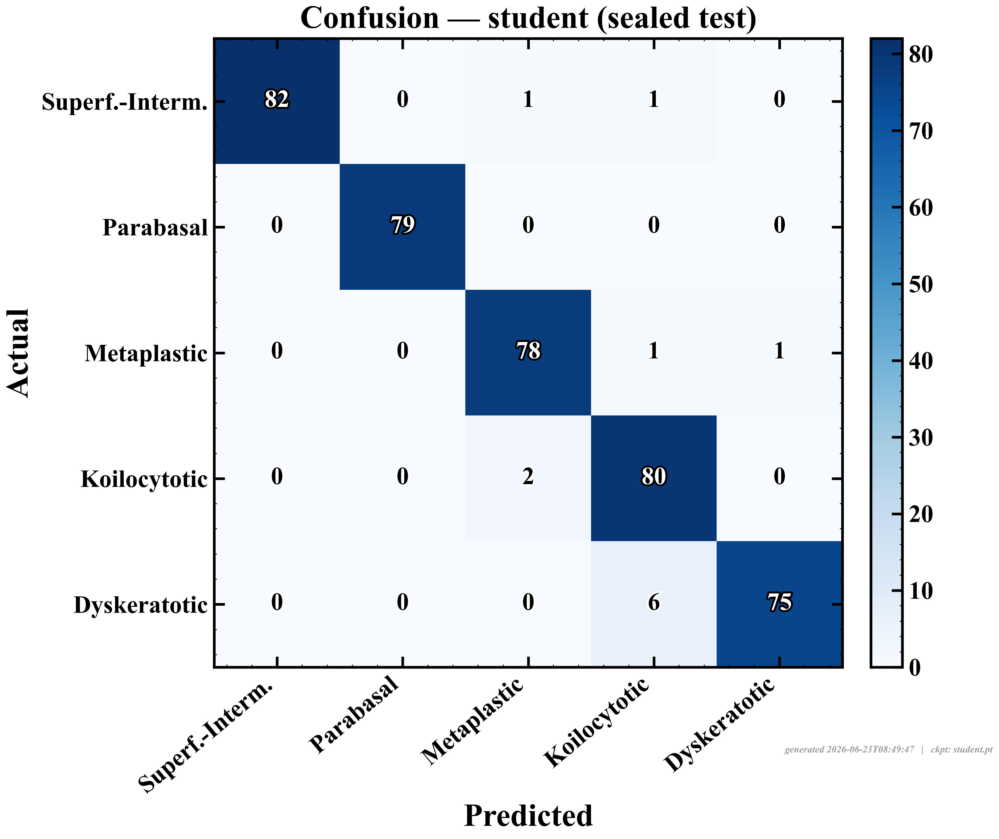

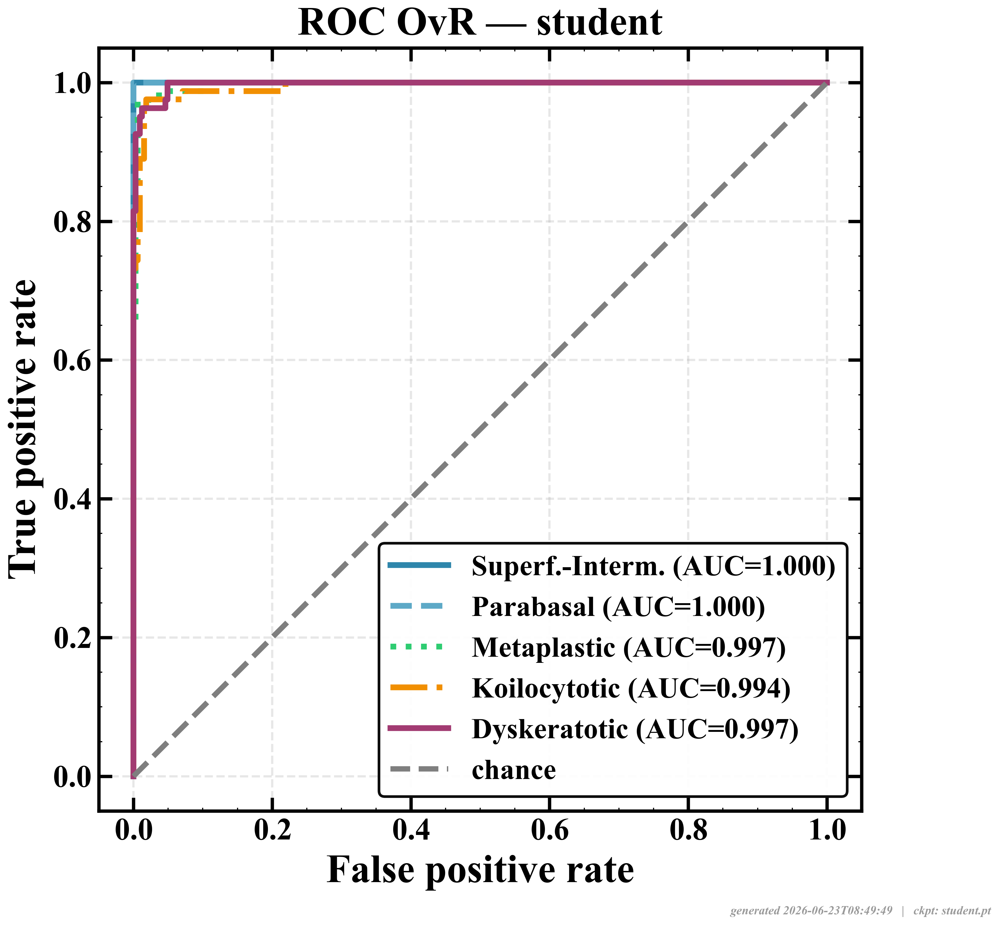

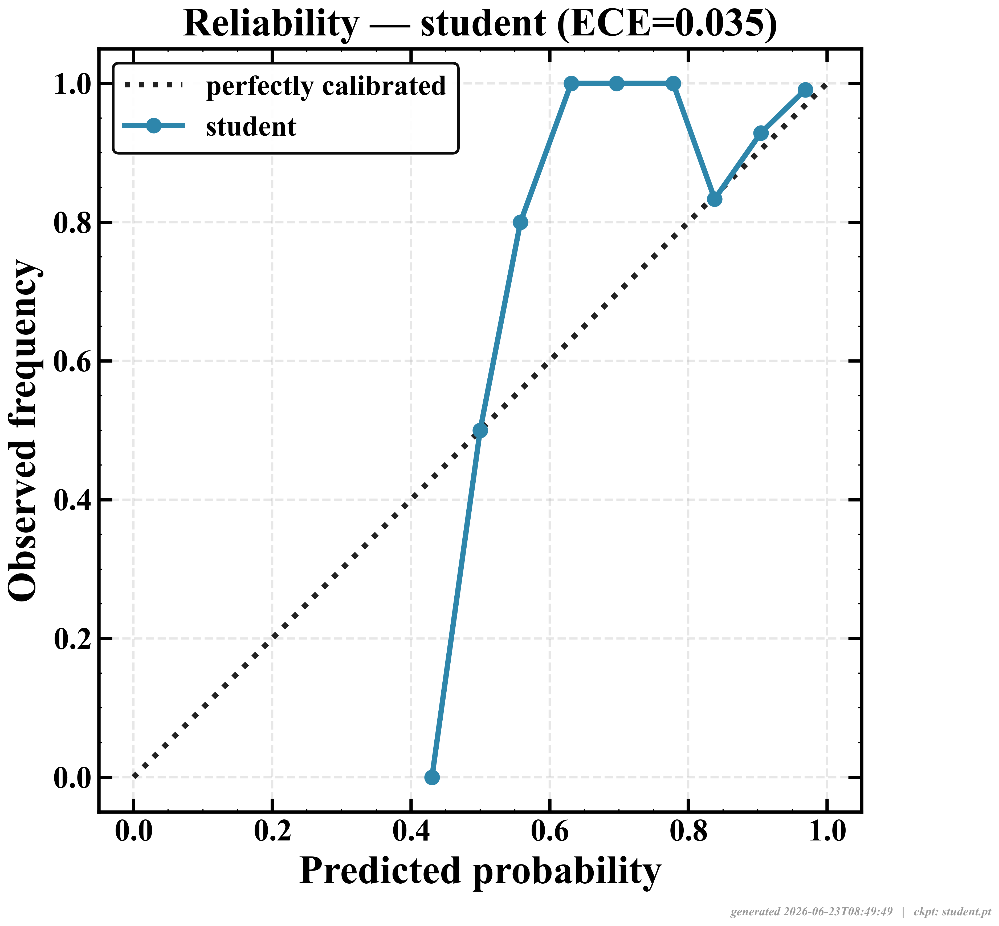

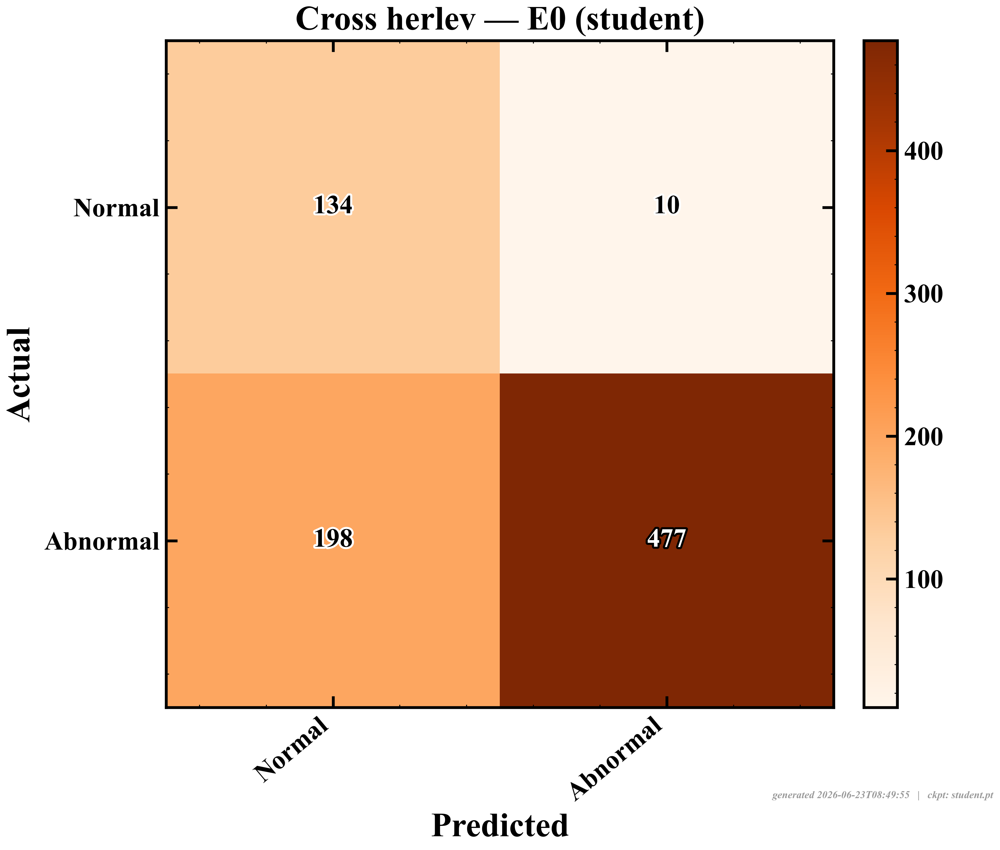

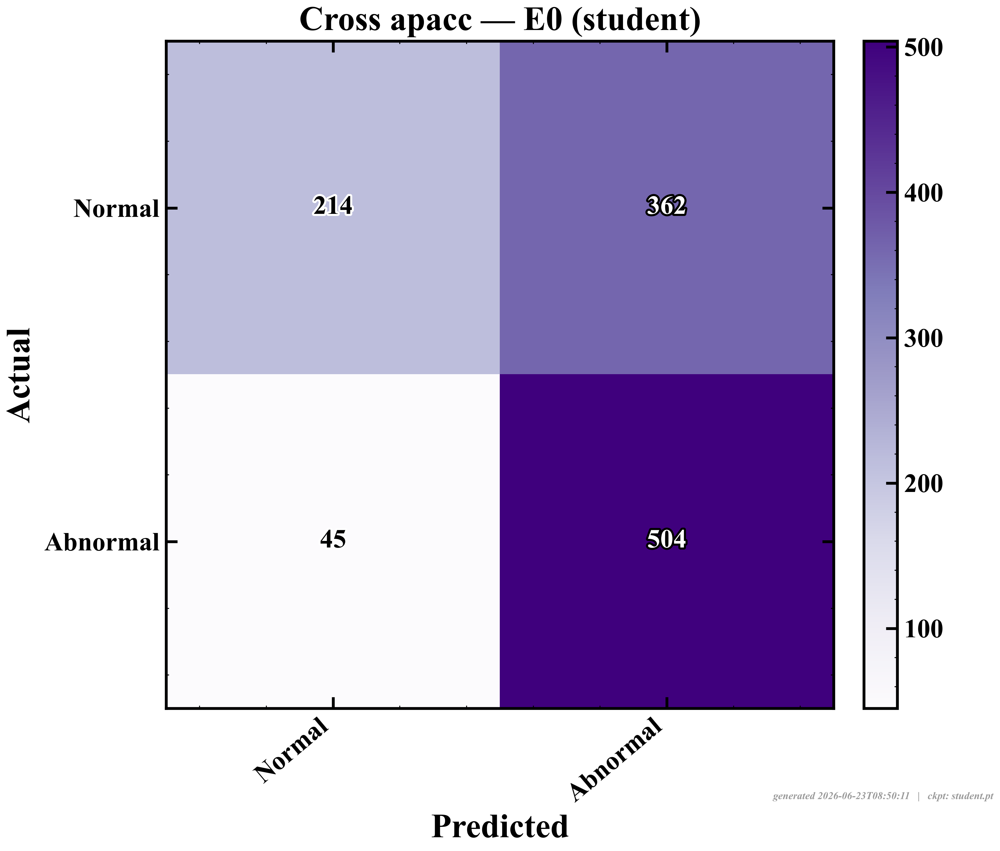

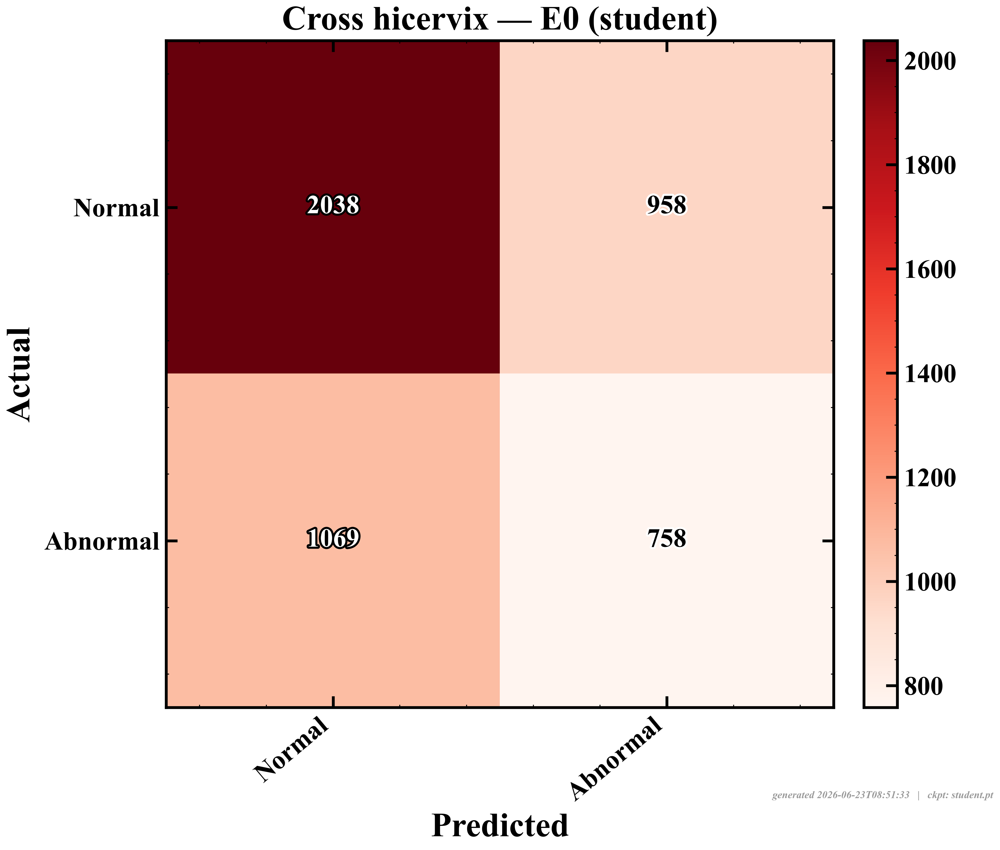

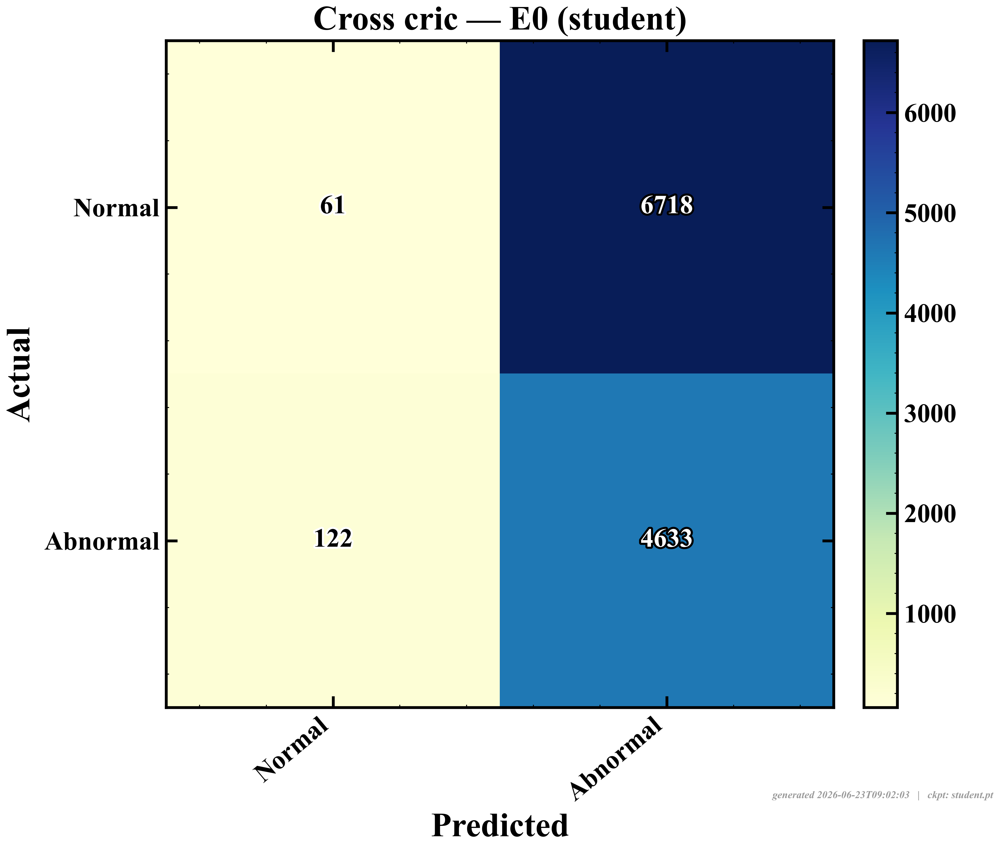

internal-vs-external delta (E0): {
 "herlev": {
  "accuracy": {
   "internal": 0.9901477832512315,
   "external": 0.746031746031746,
   "delta": -0.2441160372194855
  },
  "balanced_accuracy": {
   "internal": 0.989749804337398,
   "external": 0.8186111111111112,
   "delta": -0.17113869322628683
  },
  "macro_f1": {
   "internal": 0.989749804337398,
   "external": 0.6920117444568188,
   "delta": -0.2977380598805792
  },
  "sensitivity": {
   "internal": 0.9877300613496932,
   "external": 0.7066666666666667,
   "delta": -0.28106339468302655
  },
  "specificity": {
   "internal": 0.9917695473251029,
   "external": 0.9305555555555556,
   "delta": -0.06121399176954734
  },
  "auroc": {
   "internal": 0.9976015552021005,
   "external": 0.9306069958847738,
   "delta": -0.06699455931732667
  }
 },
 "apacc": {
  "accuracy": {
   "internal": 0.9901477832512315,
   "external": 0.6382222222222222,
   "delta": -0.3519255610290093
  },
  "balanced_accuracy": {
   "internal": 0.989749804337398,
   "

In [7]:
import run
S = run.evaluate('student')
show(os.path.join(FIG,'cm_student'), os.path.join(FIG,'roc_student'), os.path.join(FIG,'reliability_student'),
     os.path.join(FIG,'cm_cross_herlev'), os.path.join(FIG,'cm_cross_apacc'),
     os.path.join(FIG,'cm_cross_hicervix'), os.path.join(FIG,'cm_cross_cric'))
print('internal-vs-external delta (E0):', json.dumps(S['internal_external_delta'], indent=1))
print('preparation-stratified E0:', S['prep_stratified_E0'])

## 5. Explainability + multimodal fusion (RQ7)
**where** (Grad-CAM family + IG/LIME/SHAP-pixel) · **why** (SHAP on morphometrics) · **cases** (exemplar,
counterfactual, ProtoPNet) · **trust** (conformal sets).

[cam] loaded student <- f:\Cervaical Cancer\results\checkpoints\run_20260622_183134\student.pt
[cam] saved gradcam -> f:\Cervaical Cancer\results\figures\cam_gradcam.png
[cam] saved gradcampp -> f:\Cervaical Cancer\results\figures\cam_gradcampp.png
[cam] saved hirescam -> f:\Cervaical Cancer\results\figures\cam_hirescam.png
[cam] saved layercam -> f:\Cervaical Cancer\results\figures\cam_layercam.png
[cam] saved eigencam -> f:\Cervaical Cancer\results\figures\cam_eigencam.png
[cam] saved scorecam -> f:\Cervaical Cancer\results\figures\cam_scorecam.png
[attribution] loaded checkpoint f:\Cervaical Cancer\results\checkpoints\run_20260622_183134\student.pt
[attribution] saved f:\Cervaical Cancer\results\figures\attr_ig.png
[attribution] saved f:\Cervaical Cancer\results\figures\attr_saliency.png
[attribution] saved f:\Cervaical Cancer\results\figures\attr_occlusion.png


f:\Cervaical Cancer\src\explain\features.py:369: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(beeswarm_vals, Xe, feature_names=names, max_display=max_display,


[run] loaded student <- f:\Cervaical Cancer\results\checkpoints\run_20260622_183134\student.pt
[run] loaded student <- f:\Cervaical Cancer\results\checkpoints\run_20260622_183134\student.pt


Explainability summary -> f:\Cervaical Cancer\results\metrics\explain_summary_student.json


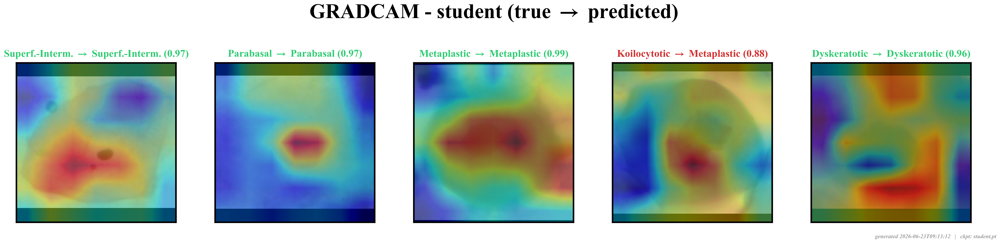

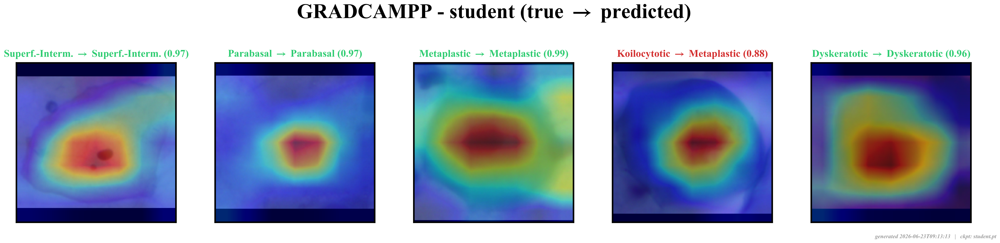

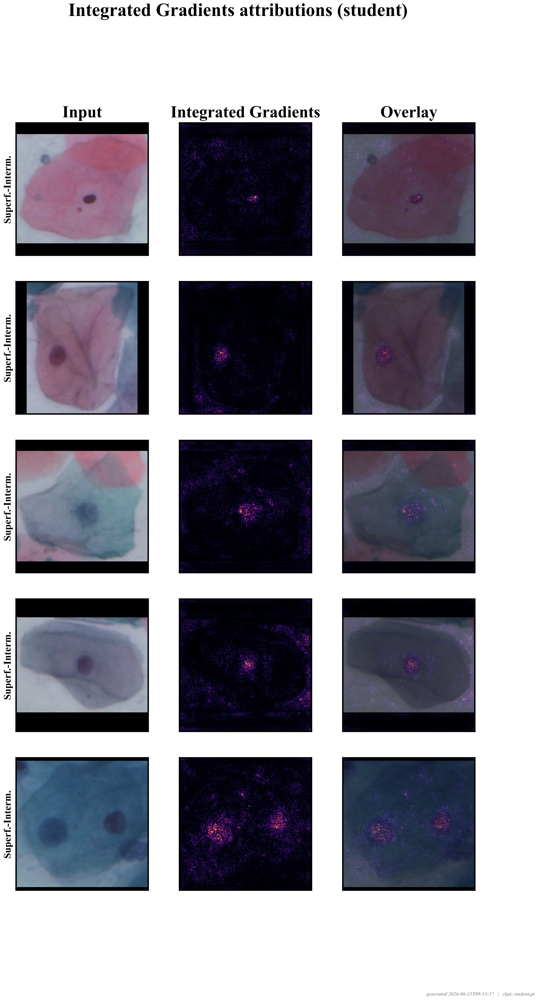

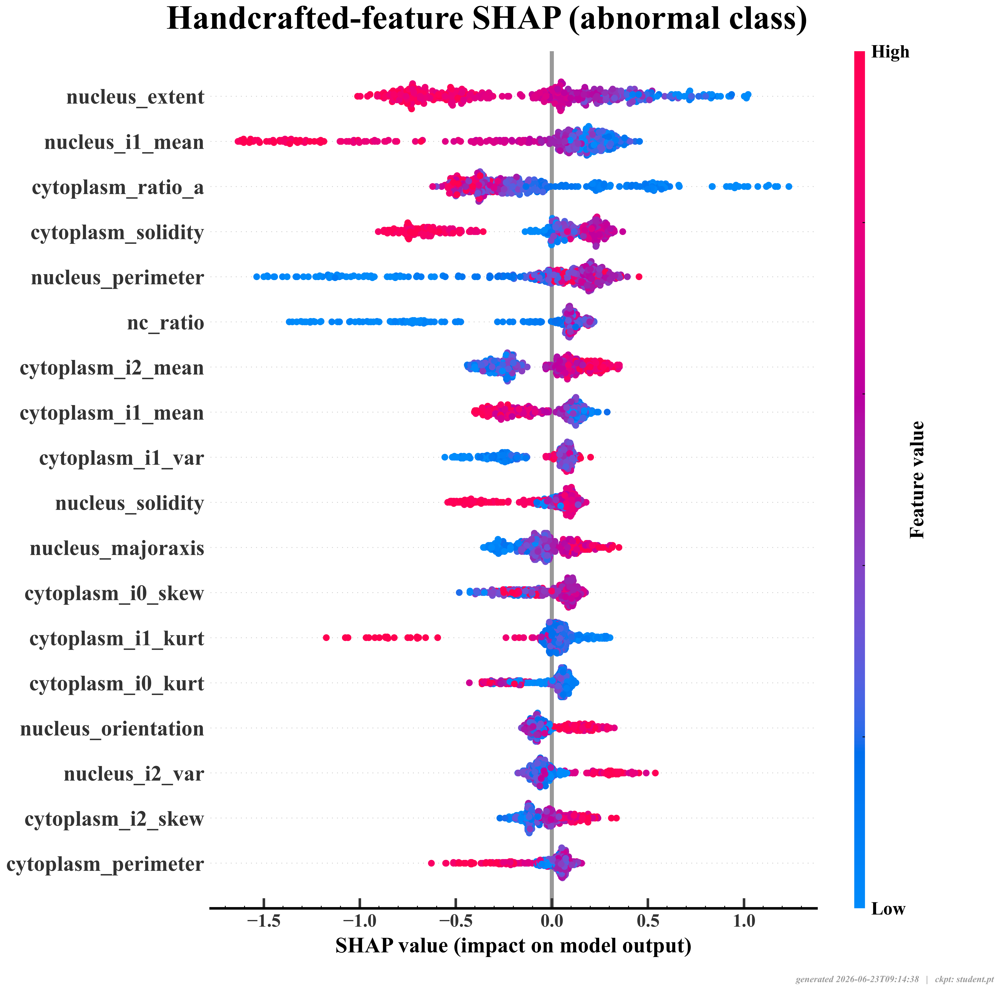

conformal: {'method': 'aps', 'alpha': 0.1, 'mondrian': True, 'qhat': [0.9773774424830772, 0.9707505044287813, 0.9908498798999262, 0.9926770396181711, 0.9785577449784155], 'coverage': 0.9532019704433498, 'avg_set_size': 2.0270935960591134, 'per_class_coverage': {'Superficial-Intermediate': 0.9642857142857143, 'Parabasal': 0.9367088607594937, 'Metaplastic': 1.0, 'Koilocytotic': 1.0, 'Dyskeratotic': 0.8641975308641975}, 'n': 406}


In [8]:
import explain
EX = explain.explain_all('student')
show(os.path.join(FIG,'cam_gradcam'), os.path.join(FIG,'cam_gradcampp'), os.path.join(FIG,'attr_ig'), os.path.join(FIG,'shap_features'))
print('conformal:', EX.get('conformal'))

In [9]:
import explain.features as feat
out = feat.run_all(save=True)          # tabular XGBoost + SHAP + permutation + PDP + late fusion (all logged JSON/CSV)
print('tabular test metrics:', out['tabular_metrics'])
print('late fusion (image vs tabular vs fused):', out['late_fusion'])

f:\Cervaical Cancer\src\explain\features.py:369: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(beeswarm_vals, Xe, feature_names=names, max_display=max_display,


tabular test metrics: {'train': {'accuracy': 1.0, 'macro_f1': 1.0, 'n': 3238}, 'val': {'accuracy': 0.8864197530864197, 'macro_f1': 0.8862748519200581, 'n': 405}, 'test': {'accuracy': 0.916256157635468, 'macro_f1': 0.9160840496865553, 'n': 406}}
late fusion (image vs tabular vs fused): {'split_kind': 'grouped', 'n_val': 405, 'n_test': 406, 'tabular_only': {'accuracy': 0.916256157635468, 'macro_f1': 0.9160840496865553, 'n': 406}, 'image_model_available': False, 'note': 'student.pt absent — tabular-only (U7 fusion gated)'}


## 6. CellGAN — minority-class rescue (RQ5)
Class-conditional DCGAN trained on the **train split only** (no test leakage). `smoke=True` is a fast sanity
check; set `smoke=False, epochs=120` for a real run, then `synthesize_minority()` tops up under-represented
classes. The RQ5 ablation arm consumes `cellgan.SynthClips` as extra training data.

[cellgan] ep 001/120  loss_D=1.177  loss_G=3.511
[cellgan] ep 002/120  loss_D=1.008  loss_G=3.020
[cellgan] ep 003/120  loss_D=0.954  loss_G=3.183
[cellgan] ep 004/120  loss_D=1.008  loss_G=3.157
[cellgan] ep 005/120  loss_D=0.977  loss_G=2.837
[cellgan] ep 006/120  loss_D=0.856  loss_G=3.035
[cellgan] ep 007/120  loss_D=0.954  loss_G=2.717
[cellgan] ep 008/120  loss_D=0.901  loss_G=3.122
[cellgan] ep 009/120  loss_D=0.961  loss_G=2.865
[cellgan] ep 010/120  loss_D=0.987  loss_G=2.869
[cellgan] ep 011/120  loss_D=0.841  loss_G=3.134
[cellgan] ep 012/120  loss_D=0.898  loss_G=2.992
[cellgan] ep 013/120  loss_D=0.850  loss_G=3.110
[cellgan] ep 014/120  loss_D=0.893  loss_G=3.198
[cellgan] ep 015/120  loss_D=0.758  loss_G=3.135
[cellgan] ep 016/120  loss_D=0.960  loss_G=2.717
[cellgan] ep 017/120  loss_D=0.762  loss_G=3.594
[cellgan] ep 018/120  loss_D=0.823  loss_G=3.325
[cellgan] ep 019/120  loss_D=0.704  loss_G=3.410
[cellgan] ep 020/120  loss_D=0.838  loss_G=3.316
[cellgan] ep 021/120

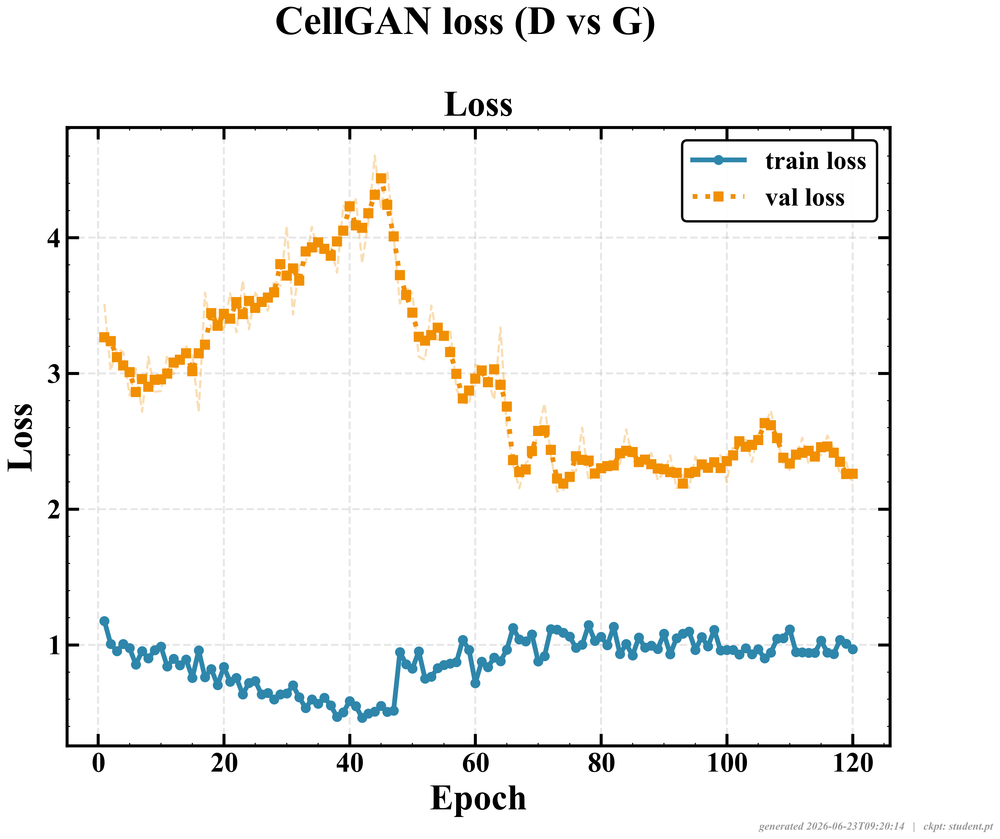

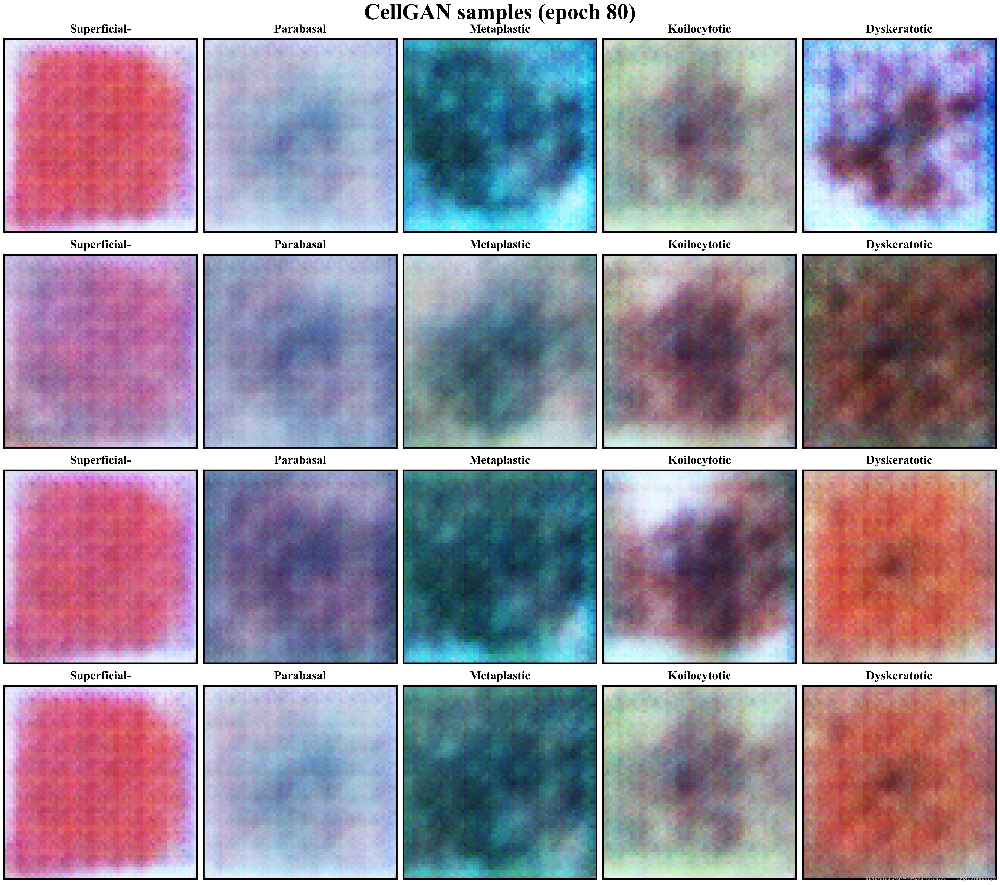

In [10]:
import cellgan
cellgan.train_cellgan(epochs=120, smoke=False)      # demo. For real rescue: smoke=False, epochs=120 (long)
cellgan.synthesize_minority()             # demo synthesis; real run: cellgan.synthesize_minority()
show(os.path.join(FIG,'cellgan_loss'))
for ep_fig in sorted(glob.glob(os.path.join(FIG,'cellgan_samples_ep*.png')))[-1:]:
    show(ep_fig[:-4])
# RQ5 augment arm (after a real GAN run): train with real + synthetic via cellgan.augmented_train_dataset()

## 7. Published-SOTA comparison (RQ6)
CCanNet / CerviXpert / MaxCerVixT reference reimplementations, trained + evaluated under the **identical**
leakage-safe protocol as the backbones. `smoke=True` is a quick check; full run trains all three. Saved to
`results/metrics/sota_comparison.json`.

In [ ]:
import ablation
ablation.sota_comparison(smoke=False)   # full: trains CCanNet, CerviXpert, MaxCerVixT (long)
# ablation.sota_comparison(smoke=True)       # quick integration check
print('saved -> results/metrics/sota_comparison.json')

Run id: 20260623_102103  ->  f:\Cervaical Cancer\results\logs\run_20260623_102103.json
Split: grouped | stain: none | student img: 224 | teacher img: 380 | EMA: True | Train counts: {'Superficial-Intermediate': 665, 'Parabasal': 629, 'Metaplastic': 634, 'Koilocytotic': 660, 'Dyskeratotic': 650} | total 3238 (test: 406 cells)
Teacher [efficientnet_b4] params: 18.5M


[teacher-s1_cmp_ccannet] ep 01/50  loss=0.7260 val_loss=0.4999  acc=0.7863 val_acc=0.8123  lr=1.0e-03  (61s)  *best


[teacher-s1_cmp_ccannet] ep 02/50  loss=0.5922 val_loss=0.4583  acc=0.8552 val_acc=0.8247  lr=1.0e-03  (39s)  *best


[teacher-s1_cmp_ccannet] ep 03/50  loss=0.5554 val_loss=0.4120  acc=0.8691 val_acc=0.8395  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_ccannet] ep 04/50  loss=0.5393 val_loss=0.3606  acc=0.8721 val_acc=0.8642  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_ccannet] ep 05/50  loss=0.5440 val_loss=0.3331  acc=0.8749 val_acc=0.8815  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_ccannet] ep 06/50  loss=0.5433 val_loss=0.3368  acc=0.8681 val_acc=0.8914  lr=1.0e-03  (40s)


[teacher-s1_cmp_ccannet] ep 07/50  loss=0.5202 val_loss=0.3489  acc=0.8879 val_acc=0.8765  lr=1.0e-03  (40s)


[teacher-s1_cmp_ccannet] ep 08/50  loss=0.5269 val_loss=0.3438  acc=0.8891 val_acc=0.8963  lr=1.0e-03  (40s)


[teacher-s1_cmp_ccannet] ep 09/50  loss=0.5167 val_loss=0.3299  acc=0.8907 val_acc=0.8790  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_ccannet] ep 10/50  loss=0.5093 val_loss=0.3147  acc=0.8956 val_acc=0.8889  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_ccannet] ep 11/50  loss=0.5197 val_loss=0.3138  acc=0.8931 val_acc=0.8963  lr=1.0e-03  (41s)  *best


[teacher-s1_cmp_ccannet] ep 12/50  loss=0.5297 val_loss=0.3127  acc=0.8799 val_acc=0.8840  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_ccannet] ep 13/50  loss=0.5129 val_loss=0.3142  acc=0.8904 val_acc=0.8889  lr=1.0e-03  (40s)


[teacher-s1_cmp_ccannet] ep 14/50  loss=0.4996 val_loss=0.3081  acc=0.8851 val_acc=0.8938  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_ccannet] ep 15/50  loss=0.4990 val_loss=0.3070  acc=0.8996 val_acc=0.8988  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_ccannet] ep 16/50  loss=0.4986 val_loss=0.3125  acc=0.8978 val_acc=0.8938  lr=1.0e-03  (40s)


[teacher-s1_cmp_ccannet] ep 17/50  loss=0.4909 val_loss=0.3109  acc=0.9009 val_acc=0.8889  lr=1.0e-03  (40s)


[teacher-s1_cmp_ccannet] ep 18/50  loss=0.4923 val_loss=0.3159  acc=0.8993 val_acc=0.8864  lr=1.0e-03  (40s)


[teacher-s1_cmp_ccannet] ep 19/50  loss=0.4835 val_loss=0.3161  acc=0.9036 val_acc=0.8914  lr=1.0e-03  (40s)


[teacher-s1_cmp_ccannet] ep 20/50  loss=0.4898 val_loss=0.3105  acc=0.9052 val_acc=0.8914  lr=1.0e-03  (40s)


[teacher-s1_cmp_ccannet] ep 21/50  loss=0.4524 val_loss=0.3121  acc=0.9206 val_acc=0.8914  lr=3.0e-04  (40s)


[teacher-s1_cmp_ccannet] ep 22/50  loss=0.4410 val_loss=0.3132  acc=0.9240 val_acc=0.8815  lr=3.0e-04  (40s)


[teacher-s1_cmp_ccannet] ep 23/50  loss=0.4393 val_loss=0.3087  acc=0.9246 val_acc=0.8889  lr=3.0e-04  (40s)
[teacher-s1_cmp_ccannet] early stop at ep 23 (best val_loss=0.3070 @ ep15)


[teacher-s2_cmp_ccannet] ep 01/120  loss=0.4405 val_loss=0.3092  acc=0.9188 val_acc=0.9037  lr=1.0e-05  (74s)  *best


[teacher-s2_cmp_ccannet] ep 02/120  loss=0.4331 val_loss=0.2973  acc=0.9287 val_acc=0.9037  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 03/120  loss=0.4380 val_loss=0.2971  acc=0.9262 val_acc=0.8963  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 04/120  loss=0.4281 val_loss=0.2932  acc=0.9280 val_acc=0.9086  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 05/120  loss=0.4280 val_loss=0.2955  acc=0.9265 val_acc=0.9037  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 06/120  loss=0.4112 val_loss=0.2897  acc=0.9385 val_acc=0.8988  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 07/120  loss=0.4226 val_loss=0.2846  acc=0.9364 val_acc=0.9111  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 08/120  loss=0.4140 val_loss=0.2761  acc=0.9345 val_acc=0.9012  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 09/120  loss=0.4141 val_loss=0.2734  acc=0.9382 val_acc=0.9086  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 10/120  loss=0.4108 val_loss=0.2700  acc=0.9336 val_acc=0.9111  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 11/120  loss=0.4099 val_loss=0.2726  acc=0.9401 val_acc=0.9062  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 12/120  loss=0.4008 val_loss=0.2728  acc=0.9444 val_acc=0.9086  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 13/120  loss=0.4049 val_loss=0.2692  acc=0.9389 val_acc=0.9086  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 14/120  loss=0.3963 val_loss=0.2720  acc=0.9404 val_acc=0.9012  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 15/120  loss=0.4033 val_loss=0.2689  acc=0.9379 val_acc=0.9062  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 16/120  loss=0.3911 val_loss=0.2676  acc=0.9503 val_acc=0.9111  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 17/120  loss=0.3910 val_loss=0.2643  acc=0.9456 val_acc=0.9136  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 18/120  loss=0.3881 val_loss=0.2648  acc=0.9456 val_acc=0.9086  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 19/120  loss=0.3837 val_loss=0.2636  acc=0.9515 val_acc=0.9111  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 20/120  loss=0.3792 val_loss=0.2589  acc=0.9515 val_acc=0.9160  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 21/120  loss=0.3791 val_loss=0.2590  acc=0.9543 val_acc=0.9136  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 22/120  loss=0.3846 val_loss=0.2563  acc=0.9509 val_acc=0.9185  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 23/120  loss=0.3830 val_loss=0.2577  acc=0.9521 val_acc=0.9111  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 24/120  loss=0.3810 val_loss=0.2549  acc=0.9481 val_acc=0.9259  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 25/120  loss=0.3783 val_loss=0.2510  acc=0.9490 val_acc=0.9210  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 26/120  loss=0.3688 val_loss=0.2533  acc=0.9561 val_acc=0.9160  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 27/120  loss=0.3740 val_loss=0.2485  acc=0.9531 val_acc=0.9185  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 28/120  loss=0.3739 val_loss=0.2481  acc=0.9537 val_acc=0.9210  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 29/120  loss=0.3682 val_loss=0.2471  acc=0.9537 val_acc=0.9210  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 30/120  loss=0.3670 val_loss=0.2488  acc=0.9543 val_acc=0.9185  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 31/120  loss=0.3696 val_loss=0.2488  acc=0.9577 val_acc=0.9210  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 32/120  loss=0.3761 val_loss=0.2447  acc=0.9534 val_acc=0.9235  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 33/120  loss=0.3663 val_loss=0.2438  acc=0.9574 val_acc=0.9185  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 34/120  loss=0.3687 val_loss=0.2481  acc=0.9558 val_acc=0.9160  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 35/120  loss=0.3661 val_loss=0.2454  acc=0.9574 val_acc=0.9160  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 36/120  loss=0.3612 val_loss=0.2437  acc=0.9558 val_acc=0.9185  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 37/120  loss=0.3659 val_loss=0.2431  acc=0.9561 val_acc=0.9185  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 38/120  loss=0.3709 val_loss=0.2418  acc=0.9555 val_acc=0.9210  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 39/120  loss=0.3584 val_loss=0.2409  acc=0.9617 val_acc=0.9185  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 40/120  loss=0.3555 val_loss=0.2420  acc=0.9617 val_acc=0.9235  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 41/120  loss=0.3619 val_loss=0.2393  acc=0.9595 val_acc=0.9210  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 42/120  loss=0.3540 val_loss=0.2389  acc=0.9626 val_acc=0.9235  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 43/120  loss=0.3562 val_loss=0.2359  acc=0.9636 val_acc=0.9185  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 44/120  loss=0.3503 val_loss=0.2377  acc=0.9676 val_acc=0.9185  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 45/120  loss=0.3510 val_loss=0.2354  acc=0.9648 val_acc=0.9185  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 46/120  loss=0.3612 val_loss=0.2327  acc=0.9580 val_acc=0.9235  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 47/120  loss=0.3547 val_loss=0.2316  acc=0.9589 val_acc=0.9235  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 48/120  loss=0.3545 val_loss=0.2322  acc=0.9599 val_acc=0.9235  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 49/120  loss=0.3571 val_loss=0.2297  acc=0.9577 val_acc=0.9210  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 50/120  loss=0.3465 val_loss=0.2290  acc=0.9670 val_acc=0.9210  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 51/120  loss=0.3469 val_loss=0.2278  acc=0.9666 val_acc=0.9235  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 52/120  loss=0.3638 val_loss=0.2251  acc=0.9571 val_acc=0.9259  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 53/120  loss=0.3483 val_loss=0.2255  acc=0.9636 val_acc=0.9235  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 54/120  loss=0.3430 val_loss=0.2245  acc=0.9648 val_acc=0.9235  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 55/120  loss=0.3395 val_loss=0.2251  acc=0.9651 val_acc=0.9235  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 56/120  loss=0.3407 val_loss=0.2244  acc=0.9685 val_acc=0.9235  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 57/120  loss=0.3524 val_loss=0.2220  acc=0.9605 val_acc=0.9235  lr=1.0e-05  (67s)  *best


[teacher-s2_cmp_ccannet] ep 58/120  loss=0.3374 val_loss=0.2196  acc=0.9704 val_acc=0.9235  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 59/120  loss=0.3390 val_loss=0.2200  acc=0.9710 val_acc=0.9259  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 60/120  loss=0.3359 val_loss=0.2197  acc=0.9676 val_acc=0.9259  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 61/120  loss=0.3360 val_loss=0.2186  acc=0.9685 val_acc=0.9235  lr=1.0e-05  (67s)  *best


[teacher-s2_cmp_ccannet] ep 62/120  loss=0.3338 val_loss=0.2166  acc=0.9691 val_acc=0.9259  lr=1.0e-05  (67s)  *best


[teacher-s2_cmp_ccannet] ep 63/120  loss=0.3292 val_loss=0.2184  acc=0.9741 val_acc=0.9259  lr=1.0e-05  (64s)


[teacher-s2_cmp_ccannet] ep 64/120  loss=0.3335 val_loss=0.2158  acc=0.9697 val_acc=0.9235  lr=1.0e-05  (64s)  *best


[teacher-s2_cmp_ccannet] ep 65/120  loss=0.3363 val_loss=0.2163  acc=0.9728 val_acc=0.9284  lr=1.0e-05  (64s)


[teacher-s2_cmp_ccannet] ep 66/120  loss=0.3309 val_loss=0.2156  acc=0.9725 val_acc=0.9259  lr=1.0e-05  (64s)  *best


[teacher-s2_cmp_ccannet] ep 67/120  loss=0.3266 val_loss=0.2146  acc=0.9725 val_acc=0.9284  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 68/120  loss=0.3353 val_loss=0.2139  acc=0.9697 val_acc=0.9259  lr=1.0e-05  (70s)  *best


[teacher-s2_cmp_ccannet] ep 69/120  loss=0.3323 val_loss=0.2132  acc=0.9682 val_acc=0.9259  lr=1.0e-05  (68s)  *best


[teacher-s2_cmp_ccannet] ep 70/120  loss=0.3307 val_loss=0.2143  acc=0.9744 val_acc=0.9235  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 71/120  loss=0.3257 val_loss=0.2128  acc=0.9725 val_acc=0.9235  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 72/120  loss=0.3350 val_loss=0.2111  acc=0.9682 val_acc=0.9259  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 73/120  loss=0.3343 val_loss=0.2110  acc=0.9688 val_acc=0.9259  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 74/120  loss=0.3318 val_loss=0.2090  acc=0.9719 val_acc=0.9259  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 75/120  loss=0.3249 val_loss=0.2086  acc=0.9728 val_acc=0.9235  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 76/120  loss=0.3259 val_loss=0.2068  acc=0.9713 val_acc=0.9284  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 77/120  loss=0.3229 val_loss=0.2058  acc=0.9759 val_acc=0.9259  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 78/120  loss=0.3250 val_loss=0.2054  acc=0.9753 val_acc=0.9259  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 79/120  loss=0.3211 val_loss=0.2039  acc=0.9747 val_acc=0.9259  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 80/120  loss=0.3250 val_loss=0.2019  acc=0.9768 val_acc=0.9259  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 81/120  loss=0.3258 val_loss=0.2021  acc=0.9747 val_acc=0.9284  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 82/120  loss=0.3196 val_loss=0.2023  acc=0.9741 val_acc=0.9284  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 83/120  loss=0.3157 val_loss=0.2016  acc=0.9787 val_acc=0.9259  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 84/120  loss=0.3318 val_loss=0.2021  acc=0.9722 val_acc=0.9284  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 85/120  loss=0.3241 val_loss=0.2022  acc=0.9734 val_acc=0.9259  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 86/120  loss=0.3220 val_loss=0.2015  acc=0.9741 val_acc=0.9259  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 87/120  loss=0.3162 val_loss=0.2022  acc=0.9784 val_acc=0.9259  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 88/120  loss=0.3217 val_loss=0.2007  acc=0.9741 val_acc=0.9259  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 89/120  loss=0.3107 val_loss=0.2001  acc=0.9809 val_acc=0.9284  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 90/120  loss=0.3074 val_loss=0.1991  acc=0.9812 val_acc=0.9284  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 91/120  loss=0.3110 val_loss=0.1988  acc=0.9799 val_acc=0.9284  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 92/120  loss=0.3131 val_loss=0.1975  acc=0.9781 val_acc=0.9309  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 93/120  loss=0.3144 val_loss=0.1969  acc=0.9790 val_acc=0.9333  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 94/120  loss=0.3175 val_loss=0.1957  acc=0.9765 val_acc=0.9333  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 95/120  loss=0.3115 val_loss=0.1952  acc=0.9815 val_acc=0.9309  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 96/120  loss=0.3132 val_loss=0.1949  acc=0.9781 val_acc=0.9333  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 97/120  loss=0.3086 val_loss=0.1943  acc=0.9787 val_acc=0.9333  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 98/120  loss=0.3094 val_loss=0.1934  acc=0.9775 val_acc=0.9309  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_ccannet] ep 99/120  loss=0.3092 val_loss=0.1959  acc=0.9796 val_acc=0.9333  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 100/120  loss=0.3107 val_loss=0.1936  acc=0.9809 val_acc=0.9309  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 101/120  loss=0.3097 val_loss=0.1934  acc=0.9812 val_acc=0.9309  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 102/120  loss=0.3080 val_loss=0.1926  acc=0.9805 val_acc=0.9333  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 103/120  loss=0.3078 val_loss=0.1924  acc=0.9802 val_acc=0.9309  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 104/120  loss=0.3110 val_loss=0.1914  acc=0.9778 val_acc=0.9333  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 105/120  loss=0.3084 val_loss=0.1903  acc=0.9815 val_acc=0.9309  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 106/120  loss=0.3126 val_loss=0.1891  acc=0.9771 val_acc=0.9309  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 107/120  loss=0.3067 val_loss=0.1886  acc=0.9793 val_acc=0.9309  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 108/120  loss=0.3011 val_loss=0.1873  acc=0.9824 val_acc=0.9309  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 109/120  loss=0.3024 val_loss=0.1871  acc=0.9855 val_acc=0.9333  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 110/120  loss=0.3036 val_loss=0.1863  acc=0.9846 val_acc=0.9333  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_ccannet] ep 111/120  loss=0.3029 val_loss=0.1869  acc=0.9802 val_acc=0.9333  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 112/120  loss=0.3021 val_loss=0.1868  acc=0.9827 val_acc=0.9333  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 113/120  loss=0.3021 val_loss=0.1872  acc=0.9821 val_acc=0.9358  lr=1.0e-05  (65s)


[teacher-s2_cmp_ccannet] ep 114/120  loss=0.3072 val_loss=0.1878  acc=0.9805 val_acc=0.9383  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 115/120  loss=0.2996 val_loss=0.1877  acc=0.9855 val_acc=0.9383  lr=1.0e-05  (66s)


[teacher-s2_cmp_ccannet] ep 116/120  loss=0.3000 val_loss=0.1868  acc=0.9842 val_acc=0.9358  lr=3.0e-06  (66s)


[teacher-s2_cmp_ccannet] ep 117/120  loss=0.3030 val_loss=0.1882  acc=0.9833 val_acc=0.9333  lr=3.0e-06  (66s)


[teacher-s2_cmp_ccannet] ep 118/120  loss=0.2995 val_loss=0.1870  acc=0.9867 val_acc=0.9333  lr=3.0e-06  (66s)


[teacher-s2_cmp_ccannet] ep 119/120  loss=0.3016 val_loss=0.1873  acc=0.9802 val_acc=0.9333  lr=3.0e-06  (66s)


[teacher-s2_cmp_ccannet] ep 120/120  loss=0.3040 val_loss=0.1876  acc=0.9827 val_acc=0.9333  lr=3.0e-06  (66s)
[teacher-s2_cmp_ccannet] early stop at ep 120 (best val_loss=0.1863 @ ep110)
== Teacher val_acc = 0.9333 ==
Student [ccannet] params: 2.0M


[student-kd_cmp_ccannet] ep 01/60  loss=1.3085 val_loss=0.9126  acc=0.6825 val_acc=0.6864  lr=5.0e-04  (67s)  *best


[student-kd_cmp_ccannet] ep 02/60  loss=1.0443 val_loss=0.7138  acc=0.7542 val_acc=0.7580  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 03/60  loss=1.0293 val_loss=0.7240  acc=0.7662 val_acc=0.7407  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 04/60  loss=0.9737 val_loss=0.6629  acc=0.7820 val_acc=0.7605  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 05/60  loss=0.9401 val_loss=0.6224  acc=0.7779 val_acc=0.7630  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 06/60  loss=0.9495 val_loss=0.6059  acc=0.7789 val_acc=0.7753  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 07/60  loss=0.8775 val_loss=0.5738  acc=0.7943 val_acc=0.7852  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 08/60  loss=0.8571 val_loss=0.5873  acc=0.8008 val_acc=0.7753  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 09/60  loss=0.8330 val_loss=0.5211  acc=0.8135 val_acc=0.7926  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 10/60  loss=0.8230 val_loss=0.5079  acc=0.8138 val_acc=0.7951  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 11/60  loss=0.7975 val_loss=0.4878  acc=0.8267 val_acc=0.8173  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 12/60  loss=0.7495 val_loss=0.4784  acc=0.8413 val_acc=0.8222  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 13/60  loss=0.7613 val_loss=0.4811  acc=0.8342 val_acc=0.8222  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 14/60  loss=0.7607 val_loss=0.4617  acc=0.8338 val_acc=0.8222  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 15/60  loss=0.7115 val_loss=0.4402  acc=0.8518 val_acc=0.8247  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 16/60  loss=0.7109 val_loss=0.4229  acc=0.8499 val_acc=0.8395  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 17/60  loss=0.6837 val_loss=0.3919  acc=0.8595 val_acc=0.8568  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 18/60  loss=0.6573 val_loss=0.3831  acc=0.8660 val_acc=0.8617  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 19/60  loss=0.6936 val_loss=0.3747  acc=0.8539 val_acc=0.8667  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 20/60  loss=0.6640 val_loss=0.3523  acc=0.8691 val_acc=0.8765  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 21/60  loss=0.6624 val_loss=0.3427  acc=0.8660 val_acc=0.8914  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 22/60  loss=0.6116 val_loss=0.3255  acc=0.8870 val_acc=0.9037  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 23/60  loss=0.6118 val_loss=0.3217  acc=0.8836 val_acc=0.9012  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 24/60  loss=0.5931 val_loss=0.3129  acc=0.8826 val_acc=0.9037  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 25/60  loss=0.6097 val_loss=0.3095  acc=0.8854 val_acc=0.9012  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 26/60  loss=0.5899 val_loss=0.3070  acc=0.8922 val_acc=0.9012  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 27/60  loss=0.5737 val_loss=0.3051  acc=0.8901 val_acc=0.9037  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 28/60  loss=0.5494 val_loss=0.3017  acc=0.8999 val_acc=0.8988  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 29/60  loss=0.5725 val_loss=0.2930  acc=0.8972 val_acc=0.9062  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 30/60  loss=0.5551 val_loss=0.2934  acc=0.8975 val_acc=0.9062  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 31/60  loss=0.5477 val_loss=0.2910  acc=0.9030 val_acc=0.9062  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 32/60  loss=0.5433 val_loss=0.2897  acc=0.9002 val_acc=0.9062  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 33/60  loss=0.5318 val_loss=0.2859  acc=0.9064 val_acc=0.9062  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 34/60  loss=0.5157 val_loss=0.2831  acc=0.9120 val_acc=0.9086  lr=5.0e-04  (26s)  *best


[student-kd_cmp_ccannet] ep 35/60  loss=0.4990 val_loss=0.2855  acc=0.9216 val_acc=0.9086  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 36/60  loss=0.4968 val_loss=0.2850  acc=0.9132 val_acc=0.9062  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 37/60  loss=0.4832 val_loss=0.2842  acc=0.9246 val_acc=0.9086  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 38/60  loss=0.4802 val_loss=0.2804  acc=0.9169 val_acc=0.9086  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 39/60  loss=0.4929 val_loss=0.2829  acc=0.9166 val_acc=0.9062  lr=5.0e-04  (27s)


[student-kd_cmp_ccannet] ep 40/60  loss=0.4713 val_loss=0.2806  acc=0.9268 val_acc=0.9012  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 41/60  loss=0.4828 val_loss=0.2773  acc=0.9197 val_acc=0.9037  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 42/60  loss=0.4607 val_loss=0.2746  acc=0.9268 val_acc=0.9037  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 43/60  loss=0.4646 val_loss=0.2724  acc=0.9271 val_acc=0.9037  lr=5.0e-04  (26s)


[student-kd_cmp_ccannet] ep 44/60  loss=0.4577 val_loss=0.2704  acc=0.9271 val_acc=0.9086  lr=5.0e-04  (26s)
[student-kd_cmp_ccannet] early stop at ep 44 (best val_accuracy=0.9086 @ ep34)
== Student val_acc = 0.9086 ==
Saved histories + curves + run log.
[run] loaded student_cmp_ccannet <- f:\Cervaical Cancer\results\checkpoints\student_cmp_ccannet.pt


[student_cmp_ccannet] 5-class acc=0.8941 macroF1=0.8945 | E0 internal acc=0.9433 | ECE 0.03170630562403251->0.027296057025447268
  herlev: E0 acc=0.684 sens=0.711 spec=0.556 excl=0.11 | E1 HG-recall=0.6855983772819473 | E-morph acc=0.6840490797546013
  apacc: E0 acc=0.518 sens=0.914 spec=0.141 excl=0.00 | E1 HG-recall=nan | E-morph acc=0.5173333333333333
  hicervix: E0 acc=0.564 sens=0.542 spec=0.577 excl=0.40 | E1 HG-recall=nan | E-morph acc=0.5617489986648865
  cric: E0 acc=0.435 sens=0.879 spec=0.123 excl=0.00 | E1 HG-recall=0.8264610971674435 | E-morph acc=None
Run id: 20260623_132228  ->  f:\Cervaical Cancer\results\logs\run_20260623_132228.json
Split: grouped | stain: none | student img: 224 | teacher img: 380 | EMA: True | Train counts: {'Superficial-Intermediate': 665, 'Parabasal': 629, 'Metaplastic': 634, 'Koilocytotic': 660, 'Dyskeratotic': 650} | total 3238 (test: 406 cells)
Teacher [efficientnet_b4] params: 18.5M


[teacher-s1_cmp_cervixpert] ep 01/50  loss=0.7260 val_loss=0.4999  acc=0.7863 val_acc=0.8123  lr=1.0e-03  (47s)  *best


[teacher-s1_cmp_cervixpert] ep 02/50  loss=0.5922 val_loss=0.4583  acc=0.8552 val_acc=0.8247  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_cervixpert] ep 03/50  loss=0.5554 val_loss=0.4120  acc=0.8691 val_acc=0.8395  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_cervixpert] ep 04/50  loss=0.5393 val_loss=0.3606  acc=0.8721 val_acc=0.8642  lr=1.0e-03  (41s)  *best


[teacher-s1_cmp_cervixpert] ep 05/50  loss=0.5440 val_loss=0.3331  acc=0.8749 val_acc=0.8815  lr=1.0e-03  (41s)  *best


[teacher-s1_cmp_cervixpert] ep 06/50  loss=0.5433 val_loss=0.3368  acc=0.8681 val_acc=0.8914  lr=1.0e-03  (40s)


[teacher-s1_cmp_cervixpert] ep 07/50  loss=0.5202 val_loss=0.3489  acc=0.8879 val_acc=0.8765  lr=1.0e-03  (40s)


[teacher-s1_cmp_cervixpert] ep 08/50  loss=0.5269 val_loss=0.3438  acc=0.8891 val_acc=0.8963  lr=1.0e-03  (40s)


[teacher-s1_cmp_cervixpert] ep 09/50  loss=0.5167 val_loss=0.3299  acc=0.8907 val_acc=0.8790  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_cervixpert] ep 10/50  loss=0.5093 val_loss=0.3147  acc=0.8956 val_acc=0.8889  lr=1.0e-03  (41s)  *best


[teacher-s1_cmp_cervixpert] ep 11/50  loss=0.5197 val_loss=0.3138  acc=0.8931 val_acc=0.8963  lr=1.0e-03  (41s)  *best


[teacher-s1_cmp_cervixpert] ep 12/50  loss=0.5297 val_loss=0.3127  acc=0.8799 val_acc=0.8840  lr=1.0e-03  (41s)  *best


[teacher-s1_cmp_cervixpert] ep 13/50  loss=0.5129 val_loss=0.3142  acc=0.8904 val_acc=0.8889  lr=1.0e-03  (40s)


[teacher-s1_cmp_cervixpert] ep 14/50  loss=0.4996 val_loss=0.3081  acc=0.8851 val_acc=0.8938  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_cervixpert] ep 15/50  loss=0.4990 val_loss=0.3070  acc=0.8996 val_acc=0.8988  lr=1.0e-03  (40s)  *best


[teacher-s1_cmp_cervixpert] ep 16/50  loss=0.4986 val_loss=0.3125  acc=0.8978 val_acc=0.8938  lr=1.0e-03  (40s)


[teacher-s1_cmp_cervixpert] ep 17/50  loss=0.4909 val_loss=0.3109  acc=0.9009 val_acc=0.8889  lr=1.0e-03  (41s)


[teacher-s1_cmp_cervixpert] ep 18/50  loss=0.4923 val_loss=0.3159  acc=0.8993 val_acc=0.8864  lr=1.0e-03  (40s)


[teacher-s1_cmp_cervixpert] ep 19/50  loss=0.4835 val_loss=0.3161  acc=0.9036 val_acc=0.8914  lr=1.0e-03  (41s)


[teacher-s1_cmp_cervixpert] ep 20/50  loss=0.4898 val_loss=0.3105  acc=0.9052 val_acc=0.8914  lr=1.0e-03  (41s)


[teacher-s1_cmp_cervixpert] ep 21/50  loss=0.4524 val_loss=0.3121  acc=0.9206 val_acc=0.8914  lr=3.0e-04  (40s)


[teacher-s1_cmp_cervixpert] ep 22/50  loss=0.4410 val_loss=0.3132  acc=0.9240 val_acc=0.8815  lr=3.0e-04  (40s)


[teacher-s1_cmp_cervixpert] ep 23/50  loss=0.4393 val_loss=0.3087  acc=0.9246 val_acc=0.8889  lr=3.0e-04  (40s)
[teacher-s1_cmp_cervixpert] early stop at ep 23 (best val_loss=0.3070 @ ep15)


[teacher-s2_cmp_cervixpert] ep 01/120  loss=0.4405 val_loss=0.3092  acc=0.9188 val_acc=0.9037  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_cervixpert] ep 02/120  loss=0.4331 val_loss=0.2973  acc=0.9287 val_acc=0.9037  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_cervixpert] ep 03/120  loss=0.4380 val_loss=0.2971  acc=0.9262 val_acc=0.8963  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_cervixpert] ep 04/120  loss=0.4281 val_loss=0.2932  acc=0.9280 val_acc=0.9086  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_cervixpert] ep 05/120  loss=0.4280 val_loss=0.2955  acc=0.9265 val_acc=0.9037  lr=1.0e-05  (66s)


[teacher-s2_cmp_cervixpert] ep 06/120  loss=0.4112 val_loss=0.2897  acc=0.9385 val_acc=0.8988  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_cervixpert] ep 07/120  loss=0.4226 val_loss=0.2846  acc=0.9364 val_acc=0.9111  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_cervixpert] ep 08/120  loss=0.4140 val_loss=0.2761  acc=0.9345 val_acc=0.9012  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_cervixpert] ep 09/120  loss=0.4141 val_loss=0.2734  acc=0.9382 val_acc=0.9086  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_cervixpert] ep 10/120  loss=0.4108 val_loss=0.2700  acc=0.9336 val_acc=0.9111  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_cervixpert] ep 11/120  loss=0.4099 val_loss=0.2726  acc=0.9401 val_acc=0.9062  lr=1.0e-05  (66s)


[teacher-s2_cmp_cervixpert] ep 12/120  loss=0.4008 val_loss=0.2728  acc=0.9444 val_acc=0.9086  lr=1.0e-05  (66s)


[teacher-s2_cmp_cervixpert] ep 13/120  loss=0.4049 val_loss=0.2692  acc=0.9389 val_acc=0.9086  lr=1.0e-05  (66s)  *best


[teacher-s2_cmp_cervixpert] ep 14/120  loss=0.3963 val_loss=0.2720  acc=0.9404 val_acc=0.9012  lr=1.0e-05  (66s)


[teacher-s2_cmp_cervixpert] ep 15/120  loss=0.4033 val_loss=0.2689  acc=0.9379 val_acc=0.9062  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_cervixpert] ep 16/120  loss=0.3911 val_loss=0.2676  acc=0.9503 val_acc=0.9111  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_cervixpert] ep 17/120  loss=0.3910 val_loss=0.2643  acc=0.9456 val_acc=0.9136  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_cervixpert] ep 18/120  loss=0.3881 val_loss=0.2648  acc=0.9456 val_acc=0.9086  lr=1.0e-05  (65s)


[teacher-s2_cmp_cervixpert] ep 19/120  loss=0.3837 val_loss=0.2636  acc=0.9515 val_acc=0.9111  lr=1.0e-05  (67s)  *best


[teacher-s2_cmp_cervixpert] ep 20/120  loss=0.3792 val_loss=0.2589  acc=0.9515 val_acc=0.9160  lr=1.0e-05  (65s)  *best


[teacher-s2_cmp_cervixpert] ep 21/120:  16%|▏| 16/102 [00:09<00:54,  1.59it/s, acc=0.961, loss=0.375

## 8. Hyperparameter optimization (U2b) — image student + tabular, refit-best + re-eval

In [ ]:
import hpo
study = hpo.run_hpo(n_trials=30, max_epochs=15, use_kd=True, retrain=True)  # image (long)
tab   = hpo.run_tabular_hpo(n_trials=40)                                    # XGBoost tabular
print('Uncomment to run (long). retrain=True re-runs the full eval on the best config.')

## 9. Ablations (A1–A9) + general model comparison (§3)
Each arm = a full training run. A1 (leakage A1 vs grouped, RQ1) and A2 (KD, RQ2/RQ6) are the headline rigor arms.

In [ ]:
import ablation
print('arms:', list(ablation.ARMS))
# ablation.run_all(arms=['A1_random_split','A2_scratch','A2_buggy_kd'])   # key rigor arms
# ablation.run_all()             # ALL 18 arms (very long)
# ablation.model_comparison()    # §3: B0/B2/MNv3/ShuffleNet/ResNet/DenseNet/Swin/MaxViT + efficiency

## 10. SSL pretraining (A9, RQ2) — SimCLR on ~46k pooled label-free crops
Then warm-start the student: `train.main(ssl_init=True)`.

In [ ]:
import selfsup
# selfsup.pretrain('efficientnet_b0', epochs=100, batch=256)   # long; saves ssl_efficientnet_b0.pt
print('SSL pool:', len(selfsup.pool_image_paths()), 'label-free crops (sipakmed+herlev+apacc+hicervix+cric)')

## 11. Results summary — every artifact (JSON / CSV / figures)

In [ ]:
for p in sorted(glob.glob(os.path.join(C.RESULTS, '**', '*'), recursive=True)):
    if os.path.isfile(p): print(os.path.relpath(p, C.PROJECT))